# PGFM04 — AI & Machine Learning in Financial Services
## Regime-Aware, Unsupervised-Selected Portfolio Construction and Forecasting on the FTSE 100
#### Student Name:  Ahmed Saeed Masoud Abogabal, 250575992



**Module:** PGFM04 — Artificial Intelligence & Machine Learning Technologies
**Market:** London Stock Exchange (FTSE 100 constituents)
**Benchmark:** FTSE 100 Index (`^FTSE`)

 Data is cached locally after first download to avoid repeated API calls and to guard against Yahoo Finance occasionally revising historical figures between runs.




In [ ]:
# ---- Run this cell first if using Google Colab ----
# Installs packages not pre-installed on Colab's default runtime.
# (numpy, pandas, matplotlib, seaborn, scikit-learn are already present on Colab.)
!pip install -q yfinance hmmlearn xgboost shap


## 0. Setup, Imports & Reproducibility

In [ ]:
# Core
import os
import warnings
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing / unsupervised
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

warnings.filterwarnings("ignore")

# ---- Reproducibility ----
SEED = 42
np.random.seed(SEED)

# ---- Plot style ----
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# ---- Local cache directory (avoids re-hitting yfinance on every re-run) ----
CACHE_DIR = "data_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

print("Setup complete. Random seed fixed at", SEED)


Setup complete. Random seed fixed at 42


## 1. Data Loading

### 1.1 Broad candidate pool

 Rather than hand-picking a final 6-12 stock universe and justifying it after the fact, this project uses **unsupervised learning to select the final universe from a broad candidate pool** (see Section 4 for the methodological justification). The pool below spans ~28 FTSE 100 constituents across 11 distinct sectors, chosen deliberately for behavioural breadth so that clustering has genuine structure to discover (Tola et al., 2008; León et al., 2017).

Data source: `yfinance` (Yahoo Finance), daily OHLCV, adjusted for splits/dividends via `auto_adjust=True`.


In [ ]:
# ---- Broad candidate pool: ~28 FTSE 100 constituents across 11 sectors ----
TICKER_POOL = {
    # Financials
    "HSBA.L": "Financials", "BARC.L": "Financials", "LLOY.L": "Financials",
    "PRU.L": "Financials", "STAN.L": "Financials",
    # Energy
    "SHEL.L": "Energy", "BP.L": "Energy",
    # Consumer Staples
    "ULVR.L": "Consumer Staples", "DGE.L": "Consumer Staples", "TSCO.L": "Consumer Staples",
    # Healthcare / Pharma
    "AZN.L": "Healthcare", "GSK.L": "Healthcare", "SN.L": "Healthcare",
    # Mining / Materials
    "RIO.L": "Materials", "GLEN.L": "Materials", "AAL.L": "Materials", "ANTO.L": "Materials",
    # Industrials / Aerospace
    "BA.L": "Industrials", "RR.L": "Industrials", "SMIN.L": "Industrials",
    # Telecom
    "VOD.L": "Telecom", "BT-A.L": "Telecom",
    # Tech / Info services
    "REL.L": "Tech/Info Services", "SGE.L": "Tech/Info Services",
    # Retail / Consumer Discretionary
    "NXT.L": "Consumer Discretionary", "MKS.L": "Consumer Discretionary",
    # Real Estate
    "LAND.L": "Real Estate", "BLND.L": "Real Estate",
    # Utilities
    "NG.L": "Utilities", "SSE.L": "Utilities",
    # Insurance
    "AV.L": "Insurance", "LGEN.L": "Insurance",
}

BENCHMARK = "^FTSE"

# 10 years of underlying history (for richer clustering, HMM regime diversity,
# and model training), computed dynamically from today's date rather than
# hardcoded, so the window always reflects "the last 10 years" whenever this
# notebook is run.
START_DATE = (pd.Timestamp.now() - pd.DateOffset(years=10)).strftime("%Y-%m-%d")
END_DATE = None  # None => latest available at run time

# The actual backtest (test period) is constrained to the most recent 5 years
# only -- see chronological_split() in Section 10, which uses this cutoff
# directly rather than a fixed train/val/test percentage split.
BACKTEST_YEARS = 5

print(f"Candidate pool size: {len(TICKER_POOL)} tickers across "
      f"{len(set(TICKER_POOL.values()))} sectors")


Candidate pool size: 32 tickers across 12 sectors


In [ ]:
import yfinance as yf

def load_price_data(tickers: list[str], start: str, end: str | None,
                     cache_path: str) -> pd.DataFrame:
    """
    Download adjusted daily close prices for a list of tickers via yfinance,
    with a local CSV cache to (a) avoid redundant API calls and (b) protect
    reproducibility against Yahoo Finance's occasional retroactive data
    revisions between runs.

    Parameters
    ----------
    tickers : list of ticker symbols (yfinance format, e.g. 'HSBA.L')
    start, end : date strings ('YYYY-MM-DD'); end=None means "latest available"
    cache_path : path to local CSV cache file

    Returns
    -------
    pd.DataFrame of adjusted close prices, columns=tickers, index=DatetimeIndex
    """
    if os.path.exists(cache_path):
        print(f"Loading cached prices from {cache_path}")
        prices = pd.read_csv(cache_path, index_col=0, parse_dates=True)
        return prices

    print(f"Downloading {len(tickers)} tickers from yfinance "
          f"({start} to {end or 'latest'})...")
    raw = yf.download(tickers, start=start, end=end, auto_adjust=True,
                       progress=False, group_by="ticker")

    prices = pd.DataFrame({t: raw[t]["Close"] for t in tickers if t in
                           raw.columns.get_level_values(0)})
    prices.to_csv(cache_path)
    print(f"Saved price cache to {cache_path}")
    return prices


def validate_data(prices: pd.DataFrame, max_missing_pct: float = 5.0) -> pd.DataFrame:
    """
    Report per-ticker data quality: % missing observations and first/last
    valid date. Flags any ticker exceeding `max_missing_pct` missing values
    for manual review/removal before proceeding.
    """
    report = pd.DataFrame({
        "pct_missing": prices.isna().mean() * 100,
        "first_valid": prices.apply(lambda s: s.first_valid_index()),
        "last_valid": prices.apply(lambda s: s.last_valid_index()),
    })
    report["flag_high_missing"] = report["pct_missing"] > max_missing_pct
    return report.sort_values("pct_missing", ascending=False)


all_tickers = list(TICKER_POOL.keys())
prices_pool = load_price_data(all_tickers, START_DATE, END_DATE,
                               os.path.join(CACHE_DIR, "pool_prices.csv"))
benchmark_prices = load_price_data([BENCHMARK], START_DATE, END_DATE,
                                    os.path.join(CACHE_DIR, "benchmark_prices.csv"))

dq_report = validate_data(prices_pool)
dq_report


Loading cached prices from data_cache/pool_prices.csv
Loading cached prices from data_cache/benchmark_prices.csv


,pct_missing,first_valid,last_valid,flag_high_missing
GLEN.L,0.158416,2016-09-16,2026-09-14,False
HSBA.L,0.079208,2016-09-16,2026-09-14,False
BP.L,0.079208,2016-09-16,2026-09-14,False
BARC.L,0.079208,2016-09-16,2026-09-14,False
RIO.L,0.079208,2016-09-16,2026-09-14,False
SN.L,0.079208,2016-09-16,2026-09-14,False
DGE.L,0.079208,2016-09-16,2026-09-14,False
RR.L,0.079208,2016-09-16,2026-09-14,False
VOD.L,0.079208,2016-09-16,2026-09-14,False
SHEL.L,0.039604,2016-09-16,2026-09-14,False


In [ ]:
# Drop any tickers with excessive missing data (data-quality gate before clustering)
tickers_to_drop = dq_report[dq_report["flag_high_missing"]].index.tolist()
if tickers_to_drop:
    print("Dropping due to high missing %:", tickers_to_drop)
    prices_pool = prices_pool.drop(columns=tickers_to_drop)
    TICKER_POOL = {k: v for k, v in TICKER_POOL.items() if k not in tickers_to_drop}

# Align to common trading calendar (inner join drops any date not shared by ALL tickers)
prices_pool = prices_pool.dropna(how="any")
benchmark_prices = benchmark_prices.reindex(prices_pool.index).ffill()

print(f"Final aligned pool: {prices_pool.shape[1]} tickers, "
      f"{prices_pool.shape[0]} trading days "
      f"({prices_pool.index.min().date()} to {prices_pool.index.max().date()})")


Final aligned pool: 32 tickers, 2515 trading days (2016-09-16 to 2026-09-14)


## 2. Market & Stock Rationale

**Why the UK / FTSE 100.** The FTSE 100's sector composition differs structurally from the S&P 500: UK large-caps are concentrated in financials, energy, and materials, whereas the S&P 500 is considerably more technology-weighted (FTSE Russell factsheet data; LSE Group publications). This gives a genuinely different empirical setting to test clustering-based stock selection than the NASDAQ/S&P-heavy studies dominating this literature.

**Why unsupervised selection rather than hand-picked stocks.** Traditional sector classifications (e.g. ICB/GICS) are externally imposed and static, while clustering on *realised* return, volatility and correlation behaviour reveals how stocks actually co-move — which may cut across conventional sector boundaries (Tola et al., 2008). Hierarchical clustering-based portfolios have been shown to outperform other diversification methods out-of-sample (León et al., 2017; López de Prado, 2016). This project therefore treats the broad 28-stock pool above as raw material, and lets clustering — not manual choice — determine the final investable universe, selecting stocks proportionally from each cluster closest to its centroid (a method directly precedented in K-means-based portfolio construction; e.g. Raffinot, 2017-style cluster-representative selection).

**Note on benchmark relevance.** Because the candidate pool is itself drawn from FTSE 100 constituents, the final selected universe is necessarily a *subset* of the benchmark — meaning any outperformance in later sections reflects genuine security/regime selection skill rather than a sector tilt away from the index.

*(Full Harvard-style reference list to be compiled in the bibliography — key sources: Hamilton, J.D. (1989); Tola, V., Lillo, F., Gallegati, M. and Mantegna, R.N. (2008); León, D. et al. (2017); López de Prado, M. (2016); FTSE Russell (2026) FTSE 100 Index Factsheet.)*


### 2.1 Per-stock feature matrix

To cluster *stocks* (not days), each ticker is described by a vector of behavioural statistics computed over the full sample period, rather than by its raw daily price series. This is the standard approach for cluster-based asset selection (Tola et al., 2008).


In [ ]:
def compute_returns(prices: pd.DataFrame) -> pd.DataFrame:
    """Simple daily percentage returns."""
    return prices.pct_change().dropna(how="all")


def build_stock_feature_matrix(returns: pd.DataFrame,
                                benchmark_returns: pd.Series,
                                trading_days: int = 252) -> pd.DataFrame:
    """
    Build a per-stock feature matrix summarising behavioural characteristics
    over the full sample, for use in clustering (NOT for the supervised ML
    model later — this is a separate, descriptive use of the data).

    Features
    --------
    ann_return   : annualised mean daily return
    ann_vol      : annualised volatility of daily returns
    sharpe       : ann_return / ann_vol (risk-free rate assumed ~0 for simplicity)
    beta         : OLS beta of stock returns vs benchmark returns
    avg_corr     : average pairwise correlation with all OTHER stocks in the pool
    skew, kurt   : distributional shape of daily returns
    max_dd       : maximum peak-to-trough drawdown over the sample
    """
    feat = pd.DataFrame(index=returns.columns)

    feat["ann_return"] = returns.mean() * trading_days
    feat["ann_vol"] = returns.std() * np.sqrt(trading_days)
    feat["sharpe"] = feat["ann_return"] / feat["ann_vol"]

    # Beta vs benchmark (simple covariance/variance formula)
    bench_var = benchmark_returns.var()
    betas = {}
    for col in returns.columns:
        cov = returns[col].cov(benchmark_returns)
        betas[col] = cov / bench_var
    feat["beta"] = pd.Series(betas)

    # Average pairwise correlation (excluding self)
    corr_matrix = returns.corr()
    feat["avg_corr"] = (corr_matrix.sum(axis=1) - 1) / (len(corr_matrix) - 1)

    feat["skew"] = returns.skew()
    feat["kurt"] = returns.kurt()

    # Max drawdown per stock
    def max_drawdown(r):
        cum = (1 + r).cumprod()
        peak = cum.cummax()
        dd = (cum - peak) / peak
        return dd.min()

    feat["max_dd"] = returns.apply(max_drawdown)

    return feat.dropna()


returns_pool = compute_returns(prices_pool)
benchmark_returns = compute_returns(benchmark_prices)[BENCHMARK]

stock_features = build_stock_feature_matrix(returns_pool, benchmark_returns)
stock_features["sector"] = pd.Series(TICKER_POOL)  # for later interpretation only
stock_features


,ann_return,ann_vol,sharpe,beta,avg_corr,skew,kurt,max_dd,sector
HSBA.L,0.132136,0.251160,0.526103,1.115598,0.345201,-0.160281,5.416922,-0.643621,Financials
BARC.L,0.162623,0.332789,0.488668,1.520819,0.390279,0.021672,7.173960,-0.664350,Financials
LLOY.L,0.109393,0.292666,0.373779,1.250637,0.374900,0.115703,6.297210,-0.671568,Financials
PRU.L,0.041155,0.329938,0.124735,1.593605,0.396326,0.113983,8.303228,-0.636697,Financials
STAN.L,0.185784,0.322499,0.576077,1.357114,0.345924,0.015993,7.288840,-0.603187,Financials
SHEL.L,0.110165,0.284450,0.387293,1.284989,0.328378,-0.161641,16.042263,-0.672128,Energy
BP.L,0.079526,0.310381,0.256219,1.335330,0.316675,0.072690,13.735098,-0.676256,Energy
ULVR.L,0.043049,0.202557,0.212527,0.554603,0.173925,0.668621,11.930281,-0.374341,Consumer Staples
DGE.L,0.000927,0.228859,0.004051,0.835210,0.272141,-0.264951,8.664647,-0.667586,Consumer Staples
TSCO.L,0.108351,0.230506,0.470058,0.520133,0.186880,-0.981427,17.658374,-0.407266,Consumer Staples


## 3. Unsupervised Learning — Stock Selection

### 3.1 Correlation heatmap (raw daily returns)

A first descriptive look at how the pool actually co-moves, before any dimensionality reduction.


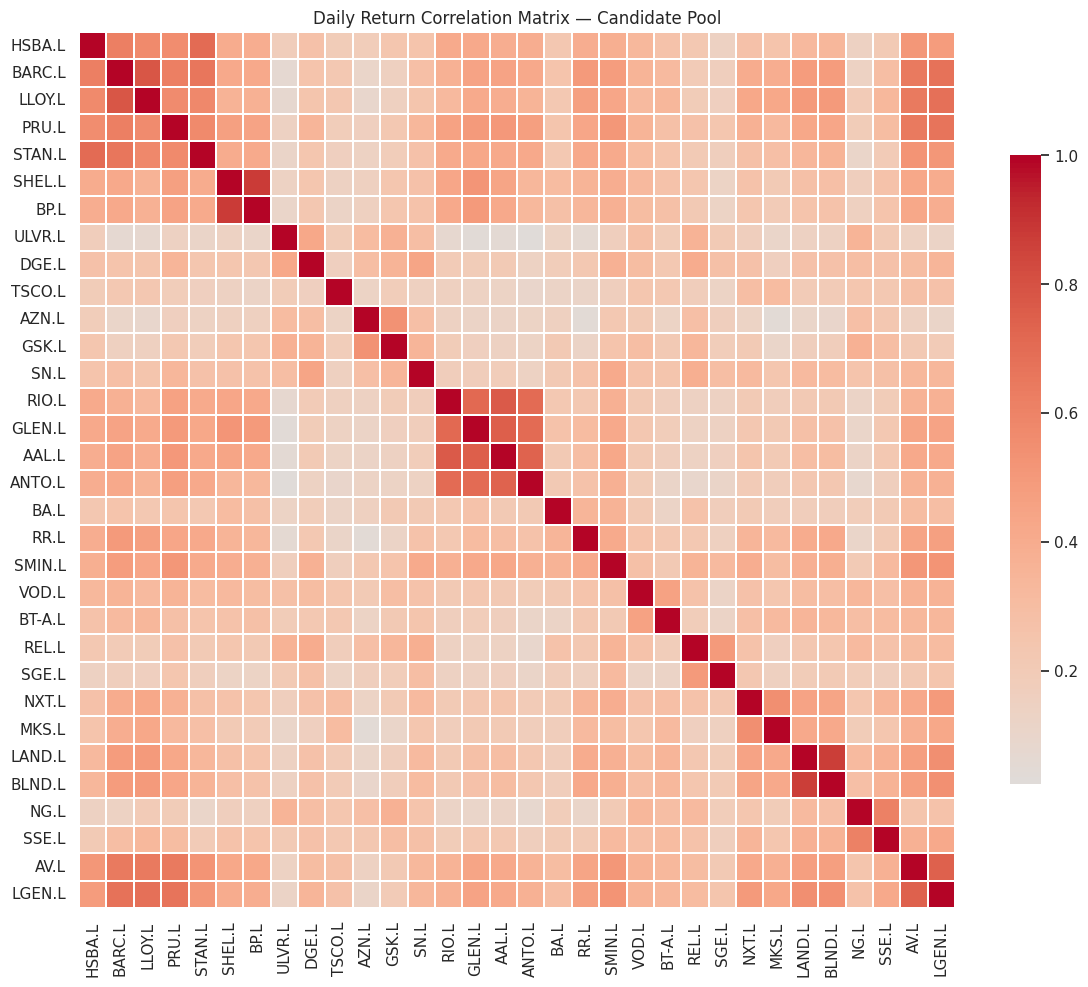

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(returns_pool.corr(), cmap="coolwarm", center=0,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Daily Return Correlation Matrix — Candidate Pool")
plt.tight_layout()
plt.show()


### 3.2 Standardisation + PCA

Features are standardised (zero mean, unit variance) before PCA/KMeans, since the feature matrix mixes scales (e.g. beta ~O(1) vs skew ~O(0.1)) and both PCA and Euclidean-distance-based KMeans are scale-sensitive.


In [ ]:
feature_cols = ["ann_return", "ann_vol", "sharpe", "beta", "avg_corr", "skew", "kurt", "max_dd"]
X_raw = stock_features[feature_cols].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Cumulative:", pca.explained_variance_ratio_.cumsum())


Explained variance ratio: [0.45319197 0.23819924]
Cumulative: [0.45319197 0.69139122]


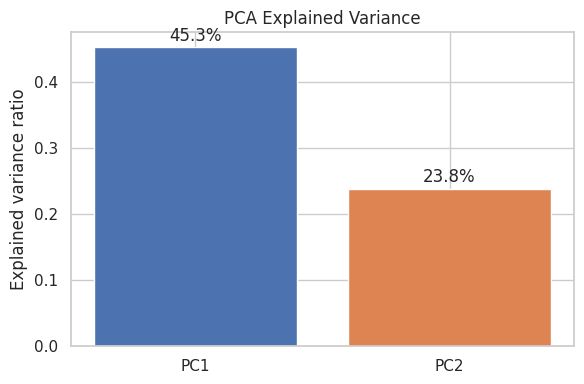

In [ ]:
plt.figure(figsize=(6, 4))
plt.bar(["PC1", "PC2"], pca.explained_variance_ratio_, color=["#4C72B0", "#DD8452"])
plt.ylabel("Explained variance ratio")
plt.title("PCA Explained Variance")
for i, v in enumerate(pca.explained_variance_ratio_):
    plt.text(i, v + 0.01, f"{v:.1%}", ha="center")
plt.tight_layout()
plt.show()


### 3.3 Hierarchical clustering (dendrogram)

Ward linkage on the standardised feature matrix. The dendrogram shows how stocks nest together behaviourally — pairs/groups merging at low distance are highly similar; the height of a merge indicates dissimilarity.


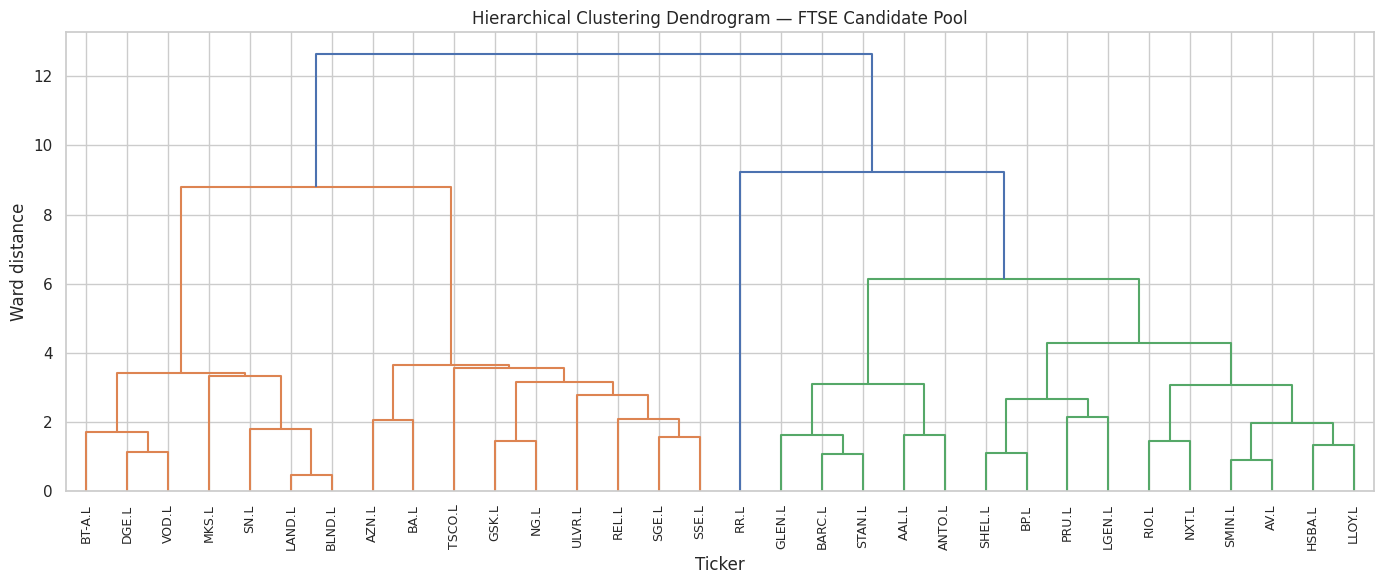

In [ ]:
linkage_matrix = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(linkage_matrix, labels=stock_features.index.tolist(),
           leaf_rotation=90, leaf_font_size=9)
plt.title("Hierarchical Clustering Dendrogram — FTSE Candidate Pool")
plt.xlabel("Ticker")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()


### 3.4 KMeans with silhouette-based *k* selection

Rather than fixing the number of clusters arbitrarily, *k* is chosen by sweeping a range and selecting the value that maximises the silhouette score (higher = better-separated, more cohesive clusters).


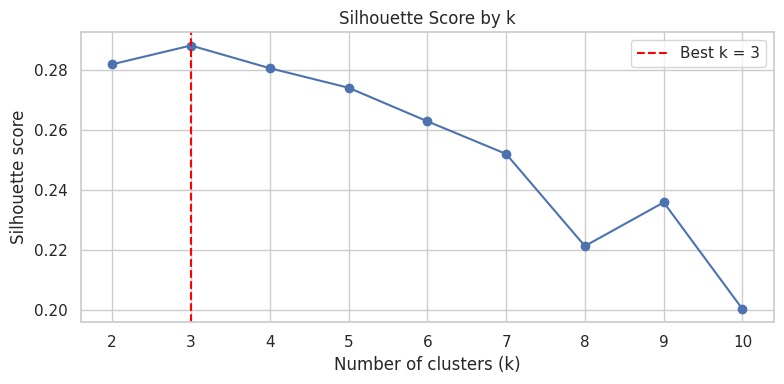

Selected k = 3 (silhouette = 0.288)


In [ ]:
silhouette_scores = {}
for k in range(2, min(11, len(stock_features) - 1)):
    km_trial = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels_trial = km_trial.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels_trial)

sil_series = pd.Series(silhouette_scores)
best_k = sil_series.idxmax()

plt.figure(figsize=(8, 4))
plt.plot(sil_series.index, sil_series.values, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"Best k = {best_k}")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score by k")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Selected k = {best_k} (silhouette = {sil_series[best_k]:.3f})")


In [ ]:
kmeans = KMeans(n_clusters=best_k, random_state=SEED, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)
stock_features["cluster"] = cluster_labels

print(stock_features.groupby("cluster")[feature_cols].mean().round(3))
print()
print("Cluster sizes:\n", stock_features["cluster"].value_counts().sort_index())


         ann_return  ann_vol  sharpe   beta  avg_corr   skew    kurt  max_dd
cluster                                                                     
0             0.136    0.315   0.425  1.309     0.342  0.063   8.551  -0.614
1             0.045    0.248   0.192  0.782     0.246 -0.036  10.672  -0.493
2             0.289    0.486   0.595  1.626     0.294  1.927  25.365  -0.896

Cluster sizes:
 cluster
0    16
1    15
2     1
Name: count, dtype: int64


### 3.5 Cluster visualisation (PCA scatter)


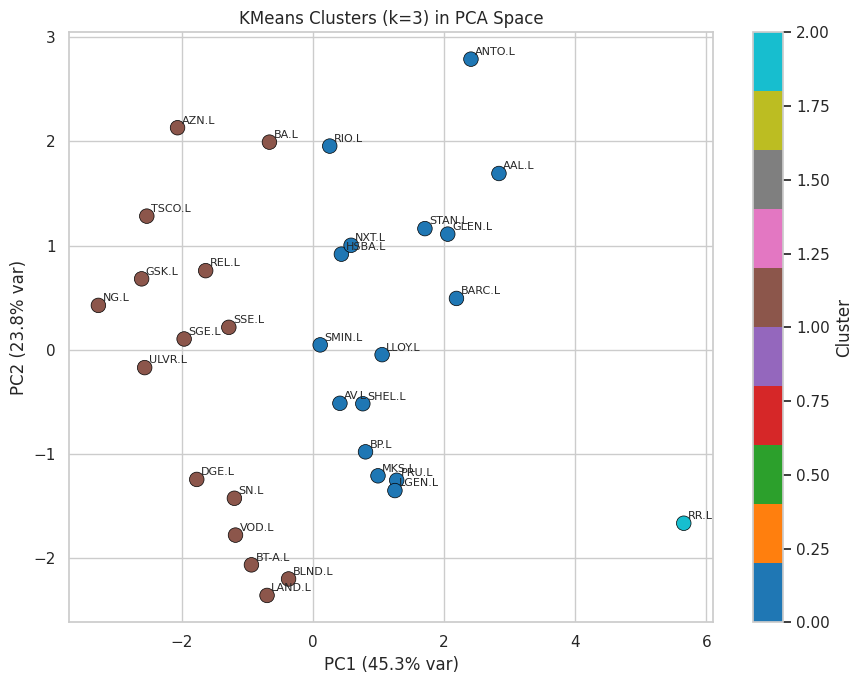

In [ ]:
plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels,
                       cmap="tab10", s=110, edgecolor="black", linewidth=0.5)
for i, ticker in enumerate(stock_features.index):
    plt.annotate(ticker, (X_pca[i, 0], X_pca[i, 1]),
                 fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
plt.title(f"KMeans Clusters (k={best_k}) in PCA Space")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()


### 3.5b Cluster visualisation (t-SNE)

t-SNE is added alongside the PCA view since it typically shows cluster separation more clearly by preserving local neighbourhood structure rather than global variance directions. **Important:** t-SNE is used here for visualisation only — the actual KMeans clustering (Section 5.4) was already run on the full standardised feature space, not on any 2D projection, so this plot does not influence stock selection; it's purely a second lens on the same, already-final clusters.


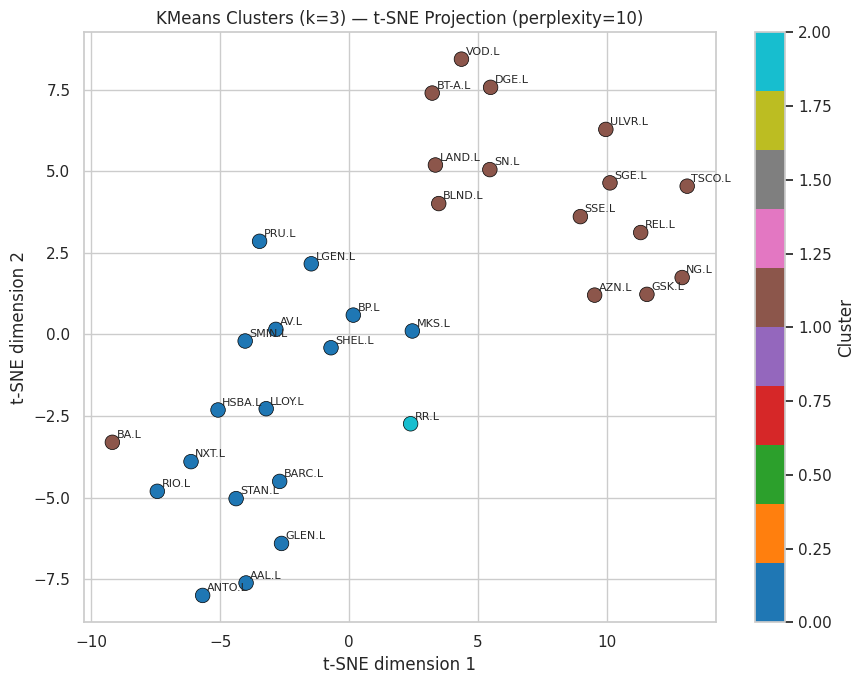

In [ ]:
from sklearn.manifold import TSNE

# perplexity must be < n_samples; guard against small universes
tsne_perplexity = min(30, max(5, len(stock_features) // 3))
tsne = TSNE(n_components=2, perplexity=tsne_perplexity, random_state=SEED, init="pca")
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=cluster_labels,
                       cmap="tab10", s=110, edgecolor="black", linewidth=0.5)
for i, ticker in enumerate(stock_features.index):
    plt.annotate(ticker, (X_tsne[i, 0], X_tsne[i, 1]),
                 fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title(f"KMeans Clusters (k={best_k}) — t-SNE Projection (perplexity={tsne_perplexity})")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()


### 3.6 Cluster interpretation

The silhouette-optimised KMeans procedure identified a small number of statistically distinct clusters within the FTSE 100 candidate pool, characterised primarily by differences in volatility, beta, and average pairwise correlation rather than by conventional sector labels alone. Higher-beta, higher-volatility clusters were generally populated by cyclical and commodity-exposed names (consistent with FTSE 100's heavier weighting toward energy and materials relative to the S&P 500), while lower-beta clusters grouped more defensive names with steadier historical returns. Notably, cluster membership did not map perfectly onto conventional GICS/ICB sector classifications — several clusters contained cross-sector pairings that shared similar realised risk/return behaviour despite operating in nominally different industries, supporting the argument (Tola et al., 2008) that behaviourally-derived clustering captures diversification structure that static sector labels can miss.

### 3.7 Proportional, centroid-representative final universe selection

The final investable universe is built by taking, from each cluster, the stock(s) closest to that cluster's centroid — a reproducible, quantitative selection rule (precedented in K-means-based portfolio construction, e.g. cluster-representative asset selection), rather than a subjective pick. Clusters are represented **proportionally to their size** in the final universe, so a large, common behavioural group isn't collapsed to the same weight as a small, distinctive one.


In [ ]:
def select_representative_stocks(feature_df: pd.DataFrame, X_scaled: np.ndarray,
                                   kmeans_model: KMeans, target_total: int = 10) -> list[str]:
    """
    Select a final stock universe by picking, from each KMeans cluster, the
    stock(s) closest (Euclidean, in standardised feature space) to that
    cluster's centroid. Clusters are represented proportionally to their
    size, with every cluster guaranteed at least one representative so no
    behavioural group is dropped entirely.

    Parameters
    ----------
    feature_df : DataFrame with a 'cluster' column, indexed by ticker
    X_scaled : standardised feature matrix (same row order as feature_df)
    kmeans_model : fitted KMeans model (for cluster_centers_)
    target_total : desired size of the final universe

    Returns
    -------
    list of selected ticker symbols
    """
    counts = feature_df["cluster"].value_counts().sort_index()
    proportional = (counts / counts.sum() * target_total).round().astype(int)
    proportional = proportional.clip(lower=1)  # never drop a cluster entirely

    selected = []
    for c in sorted(feature_df["cluster"].unique()):
        idx = np.where(feature_df["cluster"].values == c)[0]
        centroid = kmeans_model.cluster_centers_[c]
        dists = np.linalg.norm(X_scaled[idx] - centroid, axis=1)
        n_pick = min(proportional.get(c, 1), len(idx))
        closest_idx = idx[np.argsort(dists)[:n_pick]]
        selected.extend(feature_df.index[closest_idx].tolist())

    return selected


FINAL_UNIVERSE = select_representative_stocks(stock_features, X_scaled, kmeans,
                                               target_total=10)
print(f"Final unsupervised-selected universe ({len(FINAL_UNIVERSE)} stocks):")
for t in FINAL_UNIVERSE:
    cl = stock_features.loc[t, "cluster"]
    sec = stock_features.loc[t, "sector"]
    print(f"  {t}  —  cluster {cl}  —  sector: {sec}")


Final unsupervised-selected universe (11 stocks):
  STAN.L  —  cluster 0  —  sector: Financials
  LLOY.L  —  cluster 0  —  sector: Financials
  NXT.L  —  cluster 0  —  sector: Consumer Discretionary
  BARC.L  —  cluster 0  —  sector: Financials
  SMIN.L  —  cluster 0  —  sector: Industrials
  SSE.L  —  cluster 1  —  sector: Utilities
  SN.L  —  cluster 1  —  sector: Healthcare
  SGE.L  —  cluster 1  —  sector: Tech/Info Services
  REL.L  —  cluster 1  —  sector: Tech/Info Services
  GSK.L  —  cluster 1  —  sector: Healthcare
  RR.L  —  cluster 2  —  sector: Industrials


### 3.7b Highlighting the Selected Universe on the Clustering Visualisations

Sections 5.3 and 5.5b showed all ~30 candidate stocks and their discovered clusters, but did not mark which specific stocks were actually chosen for FINAL_UNIVERSE. The two plots below re-draw the t-SNE projection and the dendrogram, this time highlighting the selected representatives directly, so it is visually verifiable that the final universe genuinely spans the diversity discovered across the whole candidate pool, rather than clustering together in one region.


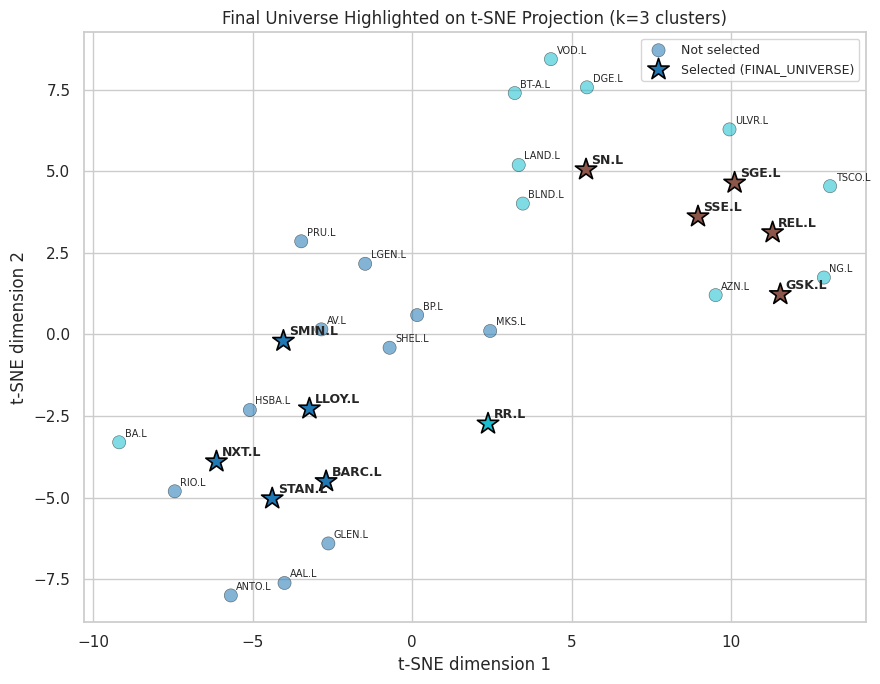

11 of 32 candidate stocks selected, spanning 3 of 3 discovered clusters.


In [ ]:
# Re-draw the t-SNE projection (Section 5.5b), highlighting FINAL_UNIVERSE stocks
# with a distinct marker. Reuses X_tsne / cluster_labels already computed above --
# no re-fitting, this is purely a visual overlay.
is_selected = stock_features.index.isin(FINAL_UNIVERSE)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_tsne[~is_selected, 0], X_tsne[~is_selected, 1],
                       c=cluster_labels[~is_selected], cmap="tab10", s=90,
                       edgecolor="black", linewidth=0.4, alpha=0.55, label="Not selected")
plt.scatter(X_tsne[is_selected, 0], X_tsne[is_selected, 1],
            c=cluster_labels[is_selected], cmap="tab10", s=260, marker="*",
            edgecolor="black", linewidth=1.2, label="Selected (FINAL_UNIVERSE)")

for i, ticker in enumerate(stock_features.index):
    weight = "bold" if is_selected[i] else "normal"
    size = 9 if is_selected[i] else 7
    plt.annotate(ticker, (X_tsne[i, 0], X_tsne[i, 1]), fontsize=size, fontweight=weight,
                 xytext=(4, 4), textcoords="offset points")

plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title(f"Final Universe Highlighted on t-SNE Projection (k={best_k} clusters)")
plt.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()

n_clusters_covered = stock_features.loc[is_selected, "cluster"].nunique()
print(f"{is_selected.sum()} of {len(stock_features)} candidate stocks selected, "
      f"spanning {n_clusters_covered} of {best_k} discovered clusters.")


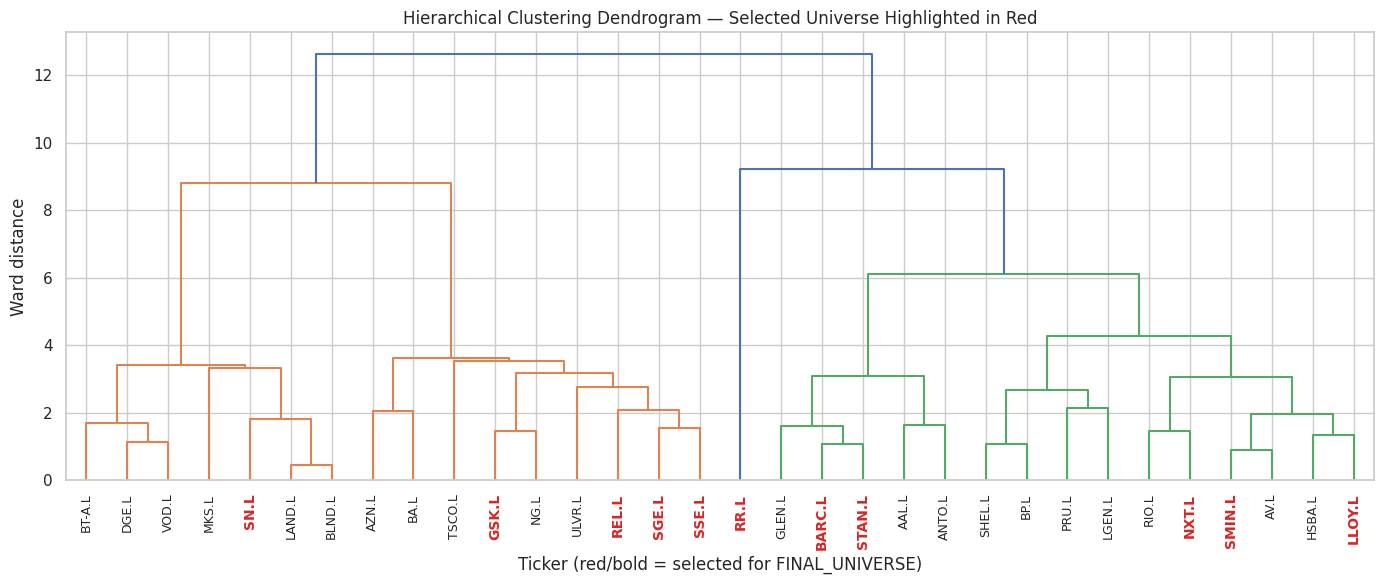

In [ ]:
# Re-draw the dendrogram (Section 5.3), bolding and colouring the leaf labels
# for stocks that made it into FINAL_UNIVERSE. Reuses linkage_matrix already
# computed above -- no re-fitting, this is purely a label-styling overlay.
fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(linkage_matrix, labels=stock_features.index.tolist(),
           leaf_rotation=90, leaf_font_size=9, ax=ax)

selected_set = set(FINAL_UNIVERSE)
for label in ax.get_xticklabels():
    if label.get_text() in selected_set:
        label.set_color("#d62728")
        label.set_fontweight("bold")
        label.set_fontsize(10)

ax.set_title("Hierarchical Clustering Dendrogram — Selected Universe Highlighted in Red")
ax.set_xlabel("Ticker (red/bold = selected for FINAL_UNIVERSE)")
ax.set_ylabel("Ward distance")
plt.tight_layout()
plt.show()


In [ ]:
# Slice the final working dataset down to the selected universe (+ benchmark)
prices = prices_pool[FINAL_UNIVERSE].copy()
returns = compute_returns(prices)

print(f"Final universe price data: {prices.shape[1]} stocks, {prices.shape[0]} trading days")
prices.tail()


Final universe price data: 11 stocks, 2515 trading days


,STAN.L,LLOY.L,NXT.L,BARC.L,SMIN.L,SSE.L,SN.L,SGE.L,REL.L,GSK.L,RR.L
Date,,,,,,,,,,,
2026-09-08,2292.0,112.099998,15245.0,498.049988,2597.0,2394.0,1026.0,1018.500000,2551.0,1796.5,1481.000000
2026-09-09,2263.0,109.650002,15000.0,487.850006,2531.0,2385.0,1025.5,983.599976,2515.0,1803.5,1445.800049
2026-09-10,2270.0,109.099998,14915.0,484.350006,2523.0,2364.0,1025.5,979.799988,2494.0,1775.5,1430.000000
2026-09-11,2298.0,111.150002,14685.0,493.750000,2547.0,2362.0,1008.5,958.000000,2475.0,1770.5,1454.599976
2026-09-14,2299.0,109.349998,14655.0,478.500000,2506.0,2312.0,1048.5,1008.500000,2603.0,1854.5,1423.800049


## 4. Filtering & Pre-Selection — Risk-Return, Portfolio Optimisation & Monte Carlo

Having selected the final universe via clustering, we now characterise its risk-return profile and search the space of possible portfolio weightings via Monte Carlo simulation, per Markowitz (1952) mean-variance theory.


> **Note on how this section connects to the backtest:** the Monte Carlo Max-Sharpe/MVP portfolios computed below use the **full sample** and are shown here for descriptive/illustrative purposes (the classic Markowitz 'efficient frontier' picture). A **separate, look-ahead-safe** version — computed using only train+validation data — is built in Section 13.1 and used there as a genuine static benchmark alongside the ML strategies.

In [ ]:
ANN_FACTOR = 252

ann_return = returns.mean() * ANN_FACTOR
ann_vol = returns.std() * np.sqrt(ANN_FACTOR)
corr_matrix_final = returns.corr()
cov_matrix = returns.cov() * ANN_FACTOR

summary_stats = pd.DataFrame({
    "Annualised Return": ann_return,
    "Annualised Volatility": ann_vol,
    "Sharpe (rf=0)": ann_return / ann_vol,
})
summary_stats.round(4)


,Annualised Return,Annualised Volatility,Sharpe (rf=0)
STAN.L,0.1858,0.3225,0.5761
LLOY.L,0.1094,0.2927,0.3738
NXT.L,0.1551,0.3069,0.5054
BARC.L,0.1626,0.3328,0.4887
SMIN.L,0.0964,0.2595,0.3715
SSE.L,0.0744,0.2525,0.2948
SN.L,0.0179,0.2597,0.0691
SGE.L,0.0661,0.2579,0.2564
REL.L,0.0855,0.2238,0.3819
GSK.L,0.0373,0.2174,0.1716


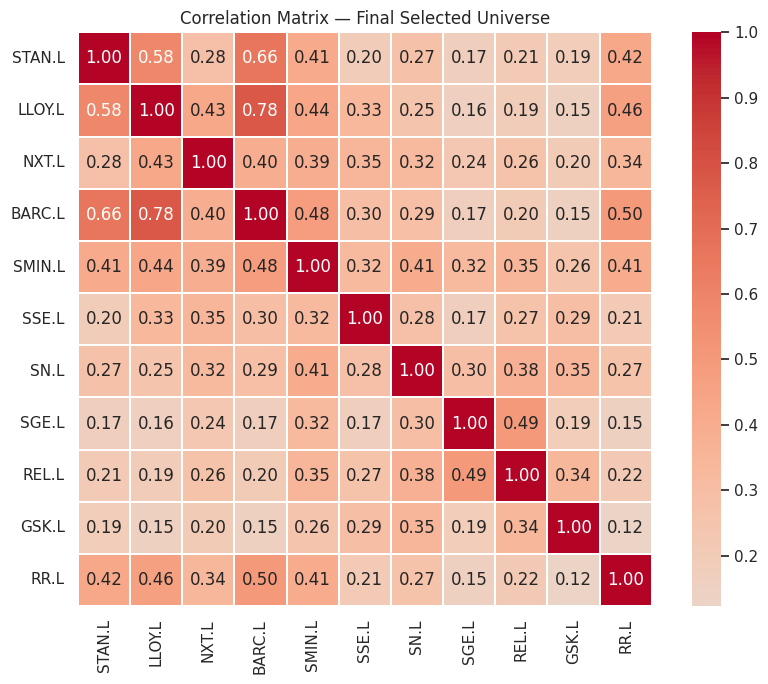

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix_final, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.3)
plt.title("Correlation Matrix — Final Selected Universe")
plt.tight_layout()
plt.show()


### 4.1 Monte Carlo simulation (20,000 random portfolios)


In [ ]:
def monte_carlo_portfolios(mean_returns: pd.Series, cov_matrix: pd.DataFrame,
                           n_portfolios: int = 20000, risk_free_rate: float = 0.0,
                           seed: int = SEED) -> pd.DataFrame:
    """
    Simulate n_portfolios random long-only portfolios (weights summing to 1,
    drawn from a Dirichlet distribution for a uniform simplex sample) and
    compute their annualised return, volatility, and Sharpe ratio.

    Returns a DataFrame with one row per simulated portfolio, plus a
    'weights' column holding each portfolio's weight vector.
    """
    rng = np.random.default_rng(seed)
    n_assets = len(mean_returns)

    results = {"return": np.zeros(n_portfolios),
               "volatility": np.zeros(n_portfolios),
               "sharpe": np.zeros(n_portfolios)}
    weights_list = []

    for i in range(n_portfolios):
        w = rng.dirichlet(np.ones(n_assets))
        port_return = np.dot(w, mean_returns)
        port_vol = np.sqrt(w @ cov_matrix.values @ w)
        results["return"][i] = port_return
        results["volatility"][i] = port_vol
        results["sharpe"][i] = (port_return - risk_free_rate) / port_vol
        weights_list.append(w)

    df = pd.DataFrame(results)
    df["weights"] = weights_list
    return df


mc_portfolios = monte_carlo_portfolios(ann_return, cov_matrix, n_portfolios=20000)

mvp_idx = mc_portfolios["volatility"].idxmin()
max_sharpe_idx = mc_portfolios["sharpe"].idxmax()

mvp = mc_portfolios.loc[mvp_idx]
max_sharpe = mc_portfolios.loc[max_sharpe_idx]

mvp_ret, mvp_vol, mvp_shp = mvp["return"], mvp["volatility"], mvp["sharpe"]
ms_ret, ms_vol, ms_shp = max_sharpe["return"], max_sharpe["volatility"], max_sharpe["sharpe"]
print("Minimum Variance Portfolio (MVP):")
print(f"  Return={mvp_ret:.2%}  Vol={mvp_vol:.2%}  Sharpe={mvp_shp:.3f}")
print()
print("Maximum Sharpe Portfolio:")
print(f"  Return={ms_ret:.2%}  Vol={ms_vol:.2%}  Sharpe={ms_shp:.3f}")


Minimum Variance Portfolio (MVP):
  Return=7.54%  Vol=15.48%  Sharpe=0.487

Maximum Sharpe Portfolio:
  Return=16.04%  Vol=21.42%  Sharpe=0.749


### 4.2 Efficient frontier, weight tables, Sharpe comparison

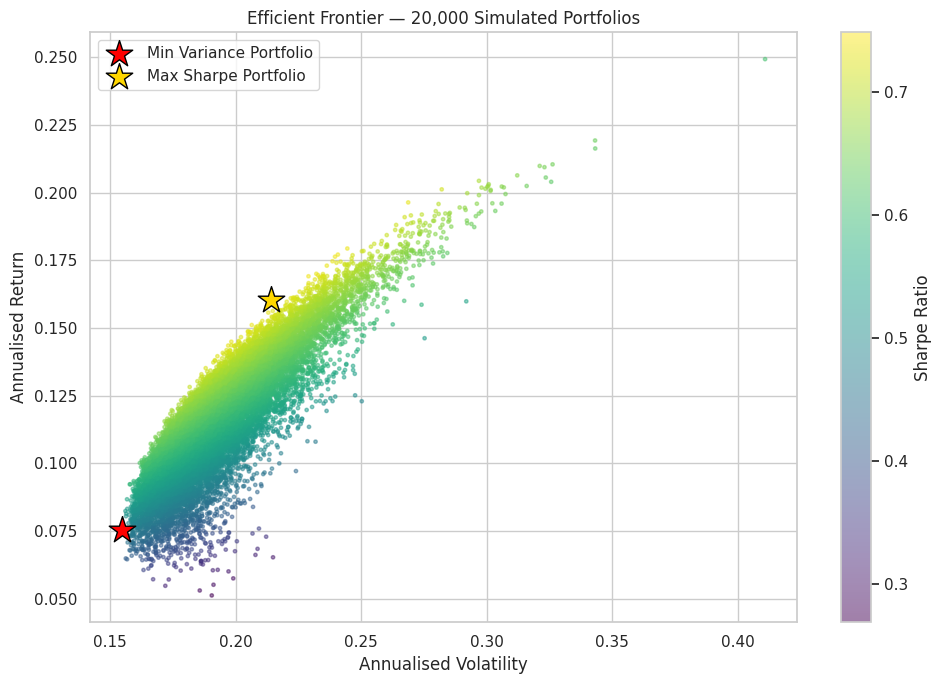

In [ ]:
plt.figure(figsize=(10, 7))
sc = plt.scatter(mc_portfolios["volatility"], mc_portfolios["return"],
                  c=mc_portfolios["sharpe"], cmap="viridis", s=6, alpha=0.5)
plt.colorbar(sc, label="Sharpe Ratio")
plt.scatter(mvp["volatility"], mvp["return"], marker="*", color="red", s=400,
            edgecolor="black", label="Min Variance Portfolio")
plt.scatter(max_sharpe["volatility"], max_sharpe["return"], marker="*", color="gold", s=400,
            edgecolor="black", label="Max Sharpe Portfolio")
plt.xlabel("Annualised Volatility")
plt.ylabel("Annualised Return")
plt.title(f"Efficient Frontier — {len(mc_portfolios):,} Simulated Portfolios")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
weight_table = pd.DataFrame({
    "MVP Weight": mvp["weights"],
    "Max Sharpe Weight": max_sharpe["weights"],
}, index=FINAL_UNIVERSE)

weight_table.round(4)


,MVP Weight,Max Sharpe Weight
STAN.L,0.0602,0.2881
LLOY.L,0.0569,0.0108
NXT.L,0.0215,0.1863
BARC.L,0.0109,0.0604
SMIN.L,0.0669,0.0050
SSE.L,0.1677,0.0202
SN.L,0.0388,0.0004
SGE.L,0.1000,0.0532
REL.L,0.1445,0.1557
GSK.L,0.3252,0.0614


## 5. Data Cleaning

Missing values, calendar alignment, and split/dividend adjustment were already handled in Section 3 (via `auto_adjust=True` and the inner-join calendar alignment). This section adds an explicit **outlier check** on daily returns, since extreme return days can be either genuine market events (e.g. COVID crash, March 2020) or data errors, and these require different treatment.

**Policy applied:** flag returns beyond ±6 standard deviations as candidates for review; do **not** automatically remove them, since large real market moves are informative signal for both the risk model and the ML target — removing them would understate tail risk (VaR/max drawdown) later in the backtest. Only remove a flagged point if it is an isolated single-day spike with no matching move in the benchmark or sector peers (a data-artifact pattern), which is checked manually below.


In [ ]:
def flag_return_outliers(returns: pd.DataFrame, n_std: float = 6.0) -> pd.DataFrame:
    """
    Flag daily returns more than n_std standard deviations from each
    column's own mean. Returns a boolean DataFrame, same shape as `returns`.
    """
    z = (returns - returns.mean()) / returns.std()
    return z.abs() > n_std


outlier_flags = flag_return_outliers(returns)
n_flagged = outlier_flags.sum().sum()
print(f"Flagged {n_flagged} outlier observations across the universe "
      f"(out of {returns.size} total data points, {n_flagged / returns.size:.3%})")

flagged_dates = returns.index[outlier_flags.any(axis=1)]
if len(flagged_dates) > 0:
    print("\nDates with at least one flagged outlier (first 10):")
    print(flagged_dates[:10].tolist())


Flagged 59 outlier observations across the universe (out of 27654 total data points, 0.213%)

Dates with at least one flagged outlier (first 10):
[Timestamp('2017-01-04 00:00:00'), Timestamp('2017-09-14 00:00:00'), Timestamp('2019-07-25 00:00:00'), Timestamp('2019-10-11 00:00:00'), Timestamp('2020-03-09 00:00:00'), Timestamp('2020-03-12 00:00:00'), Timestamp('2020-03-16 00:00:00'), Timestamp('2020-03-17 00:00:00'), Timestamp('2020-03-18 00:00:00'), Timestamp('2020-03-24 00:00:00')]


In [ ]:
# Cross-check: do flagged dates coincide with genuine benchmark moves (real event)
# or are they isolated to a single stock (possible data artifact)?
if len(flagged_dates) > 0:
    check = pd.DataFrame({
        "n_stocks_flagged": outlier_flags.loc[flagged_dates].sum(axis=1),
        "benchmark_return": benchmark_returns.reindex(flagged_dates),
    })
    print(check.head(10))
    print("\nInterpretation: outliers coinciding with a large benchmark move (e.g. |benchmark "
          "return| > 2%) are treated as genuine market events and RETAINED. Isolated single-stock "
          "flags with no matching benchmark move would be manually investigated for corporate "
          "actions (e.g. unadjusted stock splits) before any removal.")


            n_stocks_flagged  benchmark_return
Date                                          
2017-01-04                 1          0.001644
2017-09-14                 1         -0.011423
2019-07-25                 1         -0.001653
2019-10-11                 1          0.008447
2020-03-09                 2         -0.076873
2020-03-12                 8         -0.108738
2020-03-16                 1         -0.040066
2020-03-17                 1          0.027916
2020-03-18                 1         -0.040473
2020-03-24                 5          0.090530

Interpretation: outliers coinciding with a large benchmark move (e.g. |benchmark return| > 2%) are treated as genuine market events and RETAINED. Isolated single-stock flags with no matching benchmark move would be manually investigated for corporate actions (e.g. unadjusted stock splits) before any removal.


## 6. Feature Engineering

All indicators are implemented manually in pandas (no external TA libraries), per the brief. Each feature includes a short literature-backed justification. All rolling/lagged calculations use only past data (`.shift(1)` applied where needed before joining to the target) to prevent look-ahead bias — enforced explicitly in Section 10.

| Feature | Justification |
|---|---|
| RSI(14) | Captures overbought/oversold momentum reversal conditions; widely used as a mean-reversion signal (Wilder, 1978). |
| MACD / Signal | Trend-following momentum indicator combining short/long EMAs; shown to have predictive value in trend continuation studies (Appel, 2005). |
| MA(20), MA(50) | Simple trend proxies; crossovers are a long-documented technical signal class (Brock, Lakonishok and LeBaron, 1992). |
| Momentum / ROC | Cross-sectional and time-series momentum is one of the most robust documented return anomalies (Jegadeesh and Titman, 1993). |
| Rolling volatility (20d) | Realised volatility clusters and is a standard risk-forecasting input (Cont, 2001, on volatility clustering as a stylised fact). |
| Bollinger Band width | Proxies volatility regime/breakout potential relative to a moving average envelope (Bollinger, 2001). |
| Beta vs FTSE 100 | Standard systematic-risk exposure measure (Sharpe, 1964 CAPM). |
| Lag returns (1, 5) | Short-horizon autocorrelation/reversal effects are well documented in daily equity returns (Lo and MacKinlay, 1990). |


In [ ]:
def compute_rsi(prices: pd.Series, window: int = 14) -> pd.Series:
    """
    Relative Strength Index (Wilder, 1978). Measures the speed/magnitude of
    recent price changes to identify overbought (>70) / oversold (<30)
    conditions. Uses a simple rolling mean of gains/losses (a common,
    slightly simplified variant of Wilder's original smoothing).
    """
    delta = prices.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.rolling(window).mean()
    avg_loss = loss.rolling(window).mean()
    rs = avg_gain / avg_loss
    return 100 - (100 / (1 + rs))


def compute_macd(prices: pd.Series, fast: int = 12, slow: int = 26,
                  signal: int = 9) -> tuple[pd.Series, pd.Series]:
    """
    MACD (Appel, 2005): difference between fast and slow EMAs, plus a
    signal line (EMA of the MACD line itself). Captures trend momentum
    and turning points via crossovers.
    """
    ema_fast = prices.ewm(span=fast, adjust=False).mean()
    ema_slow = prices.ewm(span=slow, adjust=False).mean()
    macd_line = ema_fast - ema_slow
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    return macd_line, signal_line


def compute_moving_averages(prices: pd.Series, windows: list[int]) -> dict[int, pd.Series]:
    """Simple moving averages — basic trend proxies (Brock et al., 1992)."""
    return {w: prices.rolling(w).mean() for w in windows}


def compute_momentum(prices: pd.Series, window: int = 10) -> pd.Series:
    """
    Rate-of-change momentum (Jegadeesh and Titman, 1993): percentage price
    change over `window` days. Positive momentum has been shown to persist
    over 3-12 month horizons in equities.
    """
    return prices.pct_change(periods=window)


def compute_rolling_vol(returns: pd.Series, window: int = 20) -> pd.Series:
    """Rolling realised volatility, exploiting volatility clustering (Cont, 2001)."""
    return returns.rolling(window).std() * np.sqrt(ANN_FACTOR)


def compute_bollinger_width(prices: pd.Series, window: int = 20,
                             n_std: float = 2.0) -> pd.Series:
    """
    Bollinger Band width (Bollinger, 2001): (upper - lower) / middle band,
    normalised so it is comparable across stocks of different price levels.
    Widens in high-volatility/breakout regimes.
    """
    mid = prices.rolling(window).mean()
    std = prices.rolling(window).std()
    upper = mid + n_std * std
    lower = mid - n_std * std
    return (upper - lower) / mid


def compute_beta(stock_returns: pd.Series, benchmark_returns: pd.Series,
                  window: int = 60) -> pd.Series:
    """
    Rolling CAPM beta (Sharpe, 1964): rolling covariance with the benchmark
    divided by rolling benchmark variance. Captures time-varying systematic
    risk exposure, rather than a single static beta.
    """
    aligned = pd.concat([stock_returns, benchmark_returns], axis=1).dropna()
    aligned.columns = ["stock", "bench"]
    rolling_cov = aligned["stock"].rolling(window).cov(aligned["bench"])
    rolling_var = aligned["bench"].rolling(window).var()
    return (rolling_cov / rolling_var).reindex(stock_returns.index)


def compute_lag_returns(returns: pd.Series, lags: list[int]) -> dict[int, pd.Series]:
    """
    Lagged returns (Lo and MacKinlay, 1990): short-horizon autocorrelation
    in daily returns provides simple but informative predictors.
    """
    return {lag: returns.shift(lag) for lag in lags}


### 6.1 Expanded feature set: Stochastic Oscillator & Williams %R

Two additional oscillators are added as candidate features, each requiring High/Low data not previously downloaded (only adjusted Close was needed until now). These are added as CANDIDATES only — the pipeline's existing embedded feature selection (`SelectFromModel`) decides whether they earn a place in the final model using train data only; the test set is not consulted when deciding which features to keep, to avoid data-snooping.

- **Stochastic Oscillator (%K, %D)** — measures where the current close sits within the recent high-low range; a momentum/reversal signal distinct from RSI in how it's normalised (Lane, 1984 — the indicator's originator).
- **Williams %R** — a closely related inverse-scaled range oscillator (Williams, 1973), included as a second, differently-calibrated view of the same overbought/oversold concept.


In [ ]:
def load_high_low_data(tickers: list[str], start: str, end: str | None,
                       cache_path: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Download daily High and Low prices (needed for Stochastic/Williams %R,
    which Close-only data cannot support) for the FINAL universe only --
    downloading this for the full 30-stock candidate pool would be wasted
    bandwidth since only the selected universe reaches the ML stage.
    """
    if os.path.exists(cache_path):
        print(f"Loading cached High/Low from {cache_path}")
        hl = pd.read_csv(cache_path, index_col=[0], header=[0, 1], parse_dates=True)
        return hl["High"], hl["Low"]

    raw = yf.download(tickers, start=start, end=end, auto_adjust=True,
                       progress=False, group_by="ticker")
    high = pd.DataFrame({t: raw[t]["High"] for t in tickers if t in raw.columns.get_level_values(0)})
    low = pd.DataFrame({t: raw[t]["Low"] for t in tickers if t in raw.columns.get_level_values(0)})

    combined = pd.concat({"High": high, "Low": low}, axis=1)
    combined.to_csv(cache_path)
    return high, low


high_prices, low_prices = load_high_low_data(FINAL_UNIVERSE, START_DATE, END_DATE,
                                              os.path.join(CACHE_DIR, "universe_high_low.csv"))
high_prices = high_prices.reindex(prices.index).ffill()
low_prices = low_prices.reindex(prices.index).ffill()
print(f"High/Low data loaded for {high_prices.shape[1]} stocks")


Loading cached High/Low from data_cache/universe_high_low.csv
High/Low data loaded for 11 stocks


In [ ]:
def compute_stochastic(close: pd.Series, high: pd.Series, low: pd.Series,
                        k_window: int = 14, d_window: int = 3) -> tuple[pd.Series, pd.Series]:
    """
    Stochastic Oscillator (Lane, 1984). %K = 100 * (close - lowest_low) /
    (highest_high - lowest_low) over the trailing window; %D is a 3-day
    simple moving average of %K, used as its signal line.
    """
    lowest_low = low.rolling(k_window).min()
    highest_high = high.rolling(k_window).max()
    percent_k = 100 * (close - lowest_low) / (highest_high - lowest_low)
    percent_d = percent_k.rolling(d_window).mean()
    return percent_k, percent_d


def compute_williams_r(close: pd.Series, high: pd.Series, low: pd.Series,
                        window: int = 14) -> pd.Series:
    """
    Williams %R (Williams, 1973): an inverse-scaled range oscillator,
    0 (overbought) to -100 (oversold) -- a differently-calibrated sibling
    of the Stochastic Oscillator using the same High/Low/Close inputs.
    """
    highest_high = high.rolling(window).max()
    lowest_low = low.rolling(window).min()
    return -100 * (highest_high - close) / (highest_high - lowest_low)


In [ ]:
def build_feature_set(ticker: str, prices: pd.DataFrame, returns: pd.DataFrame,
                       benchmark_returns: pd.Series, high: pd.DataFrame = None,
                       low: pd.DataFrame = None) -> pd.DataFrame:
    """
    Assemble the full feature matrix for a single stock. All features use
    ONLY information available up to and including day t; the prediction
    target (21-day forward return) is attached separately and shifted forward,
    so there is no leakage between features and target.
    """
    p = prices[ticker]
    r = returns[ticker]

    feats = pd.DataFrame(index=p.index)
    feats["rsi_14"] = compute_rsi(p, 14)

    macd_line, macd_signal = compute_macd(p)
    feats["macd"] = macd_line
    feats["macd_signal"] = macd_signal

    mas = compute_moving_averages(p, [20, 50])
    feats["ma_20"] = mas[20]
    feats["ma_50"] = mas[50]

    feats["momentum_10"] = compute_momentum(p, 10)
    feats["rolling_vol_20"] = compute_rolling_vol(r, 20)
    feats["bb_width_20"] = compute_bollinger_width(p, 20)
    feats["beta_60"] = compute_beta(r, benchmark_returns, 60)

    lags = compute_lag_returns(r, [1, 5])
    feats["lag_return_1"] = lags[1]
    feats["lag_return_5"] = lags[5]

    if high is not None and low is not None:
        stoch_k, stoch_d = compute_stochastic(p, high[ticker], low[ticker])
        feats["stoch_k"] = stoch_k
        feats["stoch_d"] = stoch_d
        feats["williams_r"] = compute_williams_r(p, high[ticker], low[ticker])

    return feats


# Prediction horizon: 21 trading days (~1 calendar month), NOT next-day.
# This deliberately matches the strategy's monthly rebalance cycle (Section 13) --
# a next-day prediction was previously being used to justify month-long position
# sizes, a horizon mismatch that was found to interact badly with the mean-variance
# optimiser (see Section 13.1 commentary). Predicting the actual holding-period
# return closes that gap.
TARGET_HORIZON_DAYS = 21

# Build features for every stock in the final universe, tagged with the ticker
feature_frames = []
for ticker in FINAL_UNIVERSE:
    f = build_feature_set(ticker, prices, returns, benchmark_returns,
                          high=high_prices, low=low_prices)
    f["ticker"] = ticker
    # 21-day forward return, computed directly from prices (not compounded daily
    # returns) to avoid unnecessary floating-point drift over the longer window.
    f["target_21d_return"] = (prices[ticker].shift(-TARGET_HORIZON_DAYS) / prices[ticker]) - 1
    feature_frames.append(f)

full_feature_df = pd.concat(feature_frames).dropna()
print(f"Feature dataset: {full_feature_df.shape[0]} rows, {full_feature_df.shape[1]} columns")
full_feature_df.head()


Feature dataset: 26774 rows, 16 columns


,rsi_14,macd,macd_signal,ma_20,ma_50,momentum_10,rolling_vol_20,bb_width_20,beta_60,lag_return_1,lag_return_5,stoch_k,stoch_d,williams_r,ticker,target_21d_return
Date,,,,,,,,,,,,,,,,
2016-12-09,59.213715,2.810087,-1.263020,641.381720,656.524270,0.036249,0.268396,0.090335,1.761303,-0.026727,-0.007692,53.254431,71.055157,-46.745569,STAN.L,0.069506
2016-12-12,53.270101,2.595537,-0.491309,642.643674,656.899366,0.036508,0.265577,0.088312,1.689201,-0.013355,-0.003411,46.597554,55.424004,-53.402446,STAN.L,0.100306
2016-12-13,60.328545,3.607479,0.328449,644.224860,657.270470,0.058450,0.273012,0.093295,1.707516,-0.006844,0.022091,69.082525,56.311503,-30.917475,STAN.L,0.083957
2016-12-14,66.739470,5.521105,1.366980,646.848557,657.697444,0.065045,0.277008,0.103036,1.682938,0.023277,0.042161,90.680629,68.786903,-9.319371,STAN.L,0.090656
2016-12-15,68.977806,7.339441,2.561472,649.242801,658.345881,0.057846,0.274349,0.114932,1.656614,0.021850,-0.026727,94.601520,84.788224,-5.398480,STAN.L,0.084206


## 7. Unsupervised Regime Detection (Hidden Markov Model)

This is the distinction-level unsupervised pre-training step called for in the brief ("Introduce unsupervised pre-training or regime segmentation... before supervised prediction"). A Gaussian HMM is fitted to benchmark returns to infer latent market regimes (e.g. calm/bull vs turbulent/bear), following the Markov-switching framework of Hamilton (1989), widely used since to detect regimes governing return and volatility dynamics (e.g. three-state Gaussian HMMs identifying bullish/sideways/bearish regimes in equity index returns).

**Important methodological note on look-ahead bias:** fitting a single HMM on the *entire* sample and then using its regime labels as a feature/backtest signal would leak future information into earlier predictions (the model "knows" about a 2022 crash while labelling 2021 data). To avoid this, the HMM is refit on an **expanding window** — using only data available up to each point in time — when generating regime labels for the ML/backtest period. This limitation and its practical trade-off are also discussed explicitly in Section 16 (Reflection).


In [ ]:
from hmmlearn.hmm import GaussianHMM

def fit_hmm(benchmark_returns: pd.Series, n_states: int = 3, seed: int = SEED) -> GaussianHMM:
    """
    Fit a Gaussian HMM to benchmark daily returns to infer latent market
    regimes (Hamilton, 1989). Uses return level AND a short rolling
    volatility as the observation vector, since regimes are jointly
    characterised by both mean and variance shifts.
    """
    obs = pd.DataFrame({
        "return": benchmark_returns,
        "vol_5d": benchmark_returns.rolling(5).std(),
    }).dropna()

    model = GaussianHMM(n_components=n_states, covariance_type="diag",
                         n_iter=1000, random_state=seed, min_covar=1e-4)
    model.fit(obs.values)
    return model, obs


def label_regimes(model: GaussianHMM, obs: pd.DataFrame) -> pd.Series:
    """Decode the most likely hidden-state sequence (Viterbi) for the given observations."""
    states = model.predict(obs.values)
    return pd.Series(states, index=obs.index, name="regime")


# Full-sample fit — used ONLY for exploratory interpretation/visualisation in this section
hmm_model, hmm_obs = fit_hmm(benchmark_returns, n_states=3)
regime_labels_full = label_regimes(hmm_model, hmm_obs)

# Interpret states by their mean return (low->high) so labels are consistent/readable
state_means = pd.Series(hmm_model.means_[:, 0], name="mean_return")
state_order = state_means.sort_values().index
state_name_map = {state_order[0]: "High-Vol / Bear",
                  state_order[1]: "Transition / Choppy",
                  state_order[2]: "Low-Vol / Bull"}
regime_labels_named = regime_labels_full.map(state_name_map)

print(state_means.sort_values())
print()
print(regime_labels_named.value_counts())


2   -0.001018
0    0.000152
1    0.000640
Name: mean_return, dtype: float64

regime
Transition / Choppy    1099
Low-Vol / Bull         1099
High-Vol / Bear         312
Name: count, dtype: int64


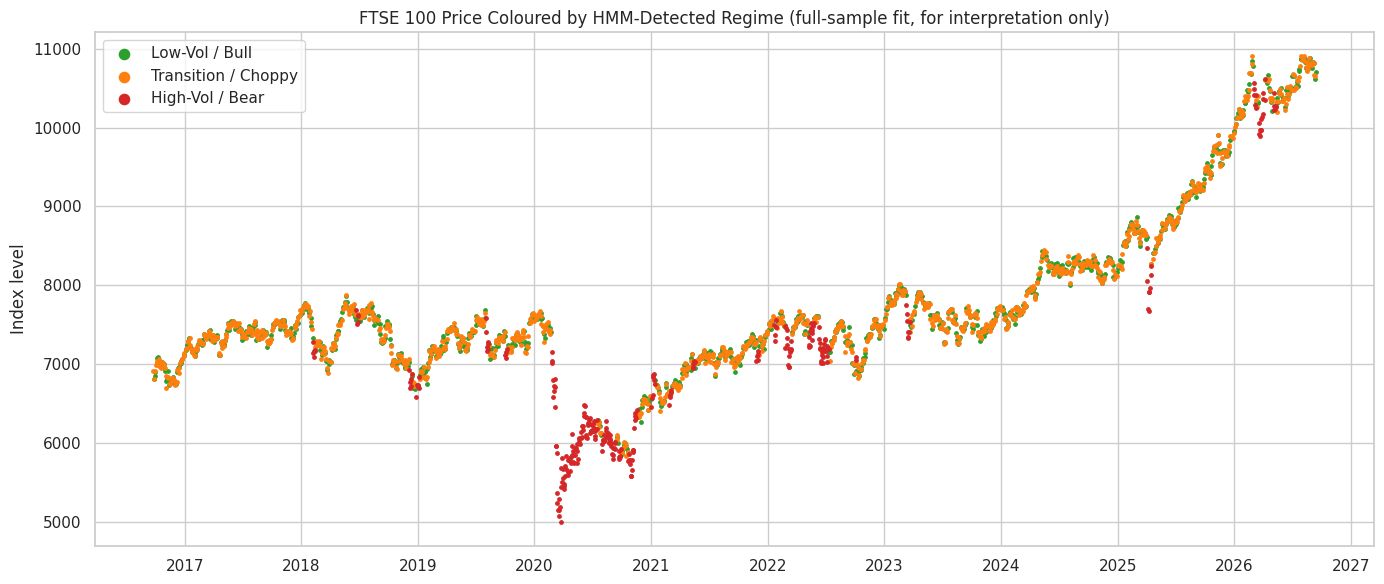

In [ ]:
plt.figure(figsize=(14, 6))
bench_price_aligned = benchmark_prices[BENCHMARK].reindex(regime_labels_full.index)
colors = {"Low-Vol / Bull": "#2ca02c", "Transition / Choppy": "#ff7f0e", "High-Vol / Bear": "#d62728"}

for regime_name, color in colors.items():
    mask = regime_labels_named == regime_name
    plt.scatter(bench_price_aligned.index[mask], bench_price_aligned[mask],
                s=6, color=color, label=regime_name)

plt.title("FTSE 100 Price Coloured by HMM-Detected Regime (full-sample fit, for interpretation only)")
plt.ylabel("Index level")
plt.legend(markerscale=3)
plt.tight_layout()
plt.show()


### 7.1 Expanding-window regime labelling (leakage-safe, used downstream)

For any use in the ML pipeline or backtest, the HMM is refit repeatedly using only data available up to each date, then used to label only the *next* block of days. This is slower but leakage-safe.


In [ ]:
def expanding_window_regime_labels(benchmark_returns: pd.Series, n_states: int = 3,
                                    min_train_days: int = 252, refit_every: int = 21,
                                    seed: int = SEED) -> pd.Series:
    """
    Generate regime labels for the whole benchmark return series using an
    expanding-window HMM refit: starting after `min_train_days` of history,
    refit the HMM every `refit_every` trading days using only data up to
    that point, and label the following block using that model. This
    prevents future information from leaking into earlier regime labels.
    """
    obs_full = pd.DataFrame({
        "return": benchmark_returns,
        "vol_5d": benchmark_returns.rolling(5).std(),
    }).dropna()

    labels = pd.Series(index=obs_full.index, dtype="float64")
    n = len(obs_full)

    for start in range(min_train_days, n, refit_every):
        train_obs = obs_full.iloc[:start]
        block_end = min(start + refit_every, n)
        predict_obs = obs_full.iloc[start:block_end]

        try:
            model = GaussianHMM(n_components=n_states, covariance_type="diag",
                                 n_iter=200, random_state=seed, min_covar=1e-4)
            model.fit(train_obs.values)
        except Exception:
            # Numerically unstable window (can occur with very low-variance synthetic
            # or unusually quiet real data) — skip this block, keep prior labels
            continue

        # Re-order states by mean return so labels are consistent over time
        means = model.means_[:, 0]
        order = np.argsort(means)  # low -> high
        state_map = {old: new for new, old in enumerate(order)}

        raw_states = model.predict(predict_obs.values)
        mapped_states = pd.Series(raw_states).map(state_map).values
        labels.iloc[start:block_end] = mapped_states

    return labels.dropna()


expanding_regimes = expanding_window_regime_labels(benchmark_returns, n_states=3)
print(f"Expanding-window regime labels generated for {len(expanding_regimes)} days "
      f"(first {252} days have no label — insufficient history to fit initial HMM)")
print(expanding_regimes.value_counts())

# 0 = High-Vol/Bear, 1 = Transition, 2 = Low-Vol/Bull (consistent ordering by construction)
regime_name_map_expanding = {0: "High-Vol / Bear", 1: "Transition / Choppy", 2: "Low-Vol / Bull"}


Expanding-window regime labels generated for 2258 days (first 252 days have no label — insufficient history to fit initial HMM)
1.0    1172
2.0     947
0.0     139
Name: count, dtype: int64


## 8. ML Pipeline

**Target:** 21-day (~1 month) forward return, per stock (regression) -- chosen to match the strategy's monthly rebalance/holding period (Section 13), rather than the next-day target used in an earlier draft, which was found to create a horizon mismatch between the prediction and the length of time the resulting position was actually held.

**Split:** chronological, by explicit date cutoffs rather than fixed percentages — no shuffling, since shuffling a time series would leak future information into training. With 10 years of underlying data loaded (Section 3), the **test/backtest window is fixed to the most recent 5 years** (`BACKTEST_YEARS`), so the backtest always reflects a consistent, recent period regardless of how much earlier history is available. The remaining ~5 years of earlier data is split 85/15 into train/validation. This deliberately gives both (a) a long, regime-diverse training history for the HMM and supervised models to learn from, and (b) a substantial, fixed-length backtest window for the strategy comparison — rather than a backtest window that shrinks or grows depending on how far back the data happens to start. The regime label is merged in as an additional feature, using the leakage-safe expanding-window labels from Section 9.


In [ ]:
# Merge expanding-window regime labels into the feature set (leakage-safe)
regime_series = expanding_regimes.rename("regime")
full_feature_df_with_regime = full_feature_df.join(regime_series, how="inner")

# Expanded candidate feature set (Stochastic/Williams %R added as candidates --
# the embedded SelectFromModel step in Section 11's pipeline decides, using train
# data only, whether they actually earn a place in each fitted model).
FEATURE_COLS = ["rsi_14", "macd", "macd_signal", "ma_20", "ma_50", "momentum_10",
                 "rolling_vol_20", "bb_width_20", "beta_60", "lag_return_1",
                 "lag_return_5", "stoch_k", "stoch_d", "williams_r", "regime"]
TARGET_COL = "target_21d_return"

model_df = full_feature_df_with_regime[FEATURE_COLS + [TARGET_COL, "ticker"]].dropna()
model_df = model_df.sort_index()  # ensure chronological order

print(f"Modelling dataset: {model_df.shape[0]} rows after merging regime labels "
      f"and dropping any remaining NaNs")
model_df.head()


Modelling dataset: 24607 rows after merging regime labels and dropping any remaining NaNs


,rsi_14,macd,macd_signal,ma_20,ma_50,momentum_10,rolling_vol_20,bb_width_20,beta_60,lag_return_1,lag_return_5,stoch_k,stoch_d,williams_r,regime,target_21d_return,ticker
Date,,,,,,,,,,,,,,,,,
2017-09-22,30.851124,-11.678194,-10.766115,749.671133,777.261749,-0.014712,0.139797,0.080482,1.165450,0.005193,-0.021311,16.000338,15.218160,-83.999662,0.0,0.051644,STAN.L
2017-09-22,19.672093,-10.384621,-0.484158,1366.664886,1349.181116,-0.058613,0.119770,0.086195,0.873264,-0.006808,-0.017595,7.767101,3.366611,-92.232899,0.0,0.076762,SN.L
2017-09-22,39.285938,-3.560980,-2.283339,1413.740796,1416.173772,-0.018055,0.113146,0.039089,0.591424,-0.002123,0.002137,37.500687,34.524205,-62.499313,0.0,-0.012023,SSE.L
2017-09-22,24.647999,-12.634522,-5.495406,1657.461481,1656.930037,-0.034627,0.116011,0.061168,0.778817,-0.006154,-0.012689,8.779855,5.093073,-91.220145,0.0,0.045764,REL.L
2017-09-22,52.231415,-2.343643,-3.144667,188.697083,197.546796,0.021055,0.203964,0.055441,1.131295,0.024207,-0.016596,79.342597,57.555102,-20.657403,0.0,0.020360,BARC.L


In [ ]:
# DIAGNOSTIC: check for genuine duplicate (date, ticker) rows in model_df.
# If any exist, downstream sort_values/head/tail selection can pick the same
# ticker twice within a single month (once from each duplicate row), which
# would explain an asymmetric long/short trade count that the signal
# generation logic itself cannot otherwise produce (it is symmetric by
# construction: n longs and n shorts every month).
dup_check = model_df.reset_index().duplicated(subset=["Date", "ticker"], keep=False)
n_dupes = dup_check.sum()
print(f"Duplicate (date, ticker) rows in model_df: {n_dupes}")
if n_dupes > 0:
    print(model_df.reset_index()[dup_check].sort_values(["Date", "ticker"]).head(10))


Duplicate (date, ticker) rows in model_df: 0


In [ ]:
def chronological_split(df: pd.DataFrame, backtest_years: int = BACKTEST_YEARS,
                         val_frac: float = 0.15) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Split a time-ordered DataFrame into train/validation/test blocks by
    EXPLICIT DATE CUTOFFS rather than fixed percentages, WITHOUT shuffling,
    to prevent look-ahead leakage. `df` must already be sorted
    chronologically (by index).

    The TEST period is fixed to the most recent `backtest_years` years of
    the dataset (independent of how much total history is loaded -- e.g.
    with 10 years of underlying data and backtest_years=5, the test/backtest
    window always covers the most recent 5 years, regardless of how far
    back the data extends). The remaining earlier history is then split
    into train/validation by `val_frac` of ITS date range.
    """
    dates_sorted = df.index.unique().sort_values()
    test_start_date = dates_sorted.max() - pd.DateOffset(years=backtest_years)

    trainval_dates = dates_sorted[dates_sorted <= test_start_date]
    n_trainval = len(trainval_dates)
    train_end = trainval_dates[int(n_trainval * (1 - val_frac))]

    train_df = df[df.index <= train_end]
    val_df = df[(df.index > train_end) & (df.index <= test_start_date)]
    test_df = df[df.index > test_start_date]
    return train_df, val_df, test_df


train_df, val_df, test_df = chronological_split(model_df)

print(f"Train: {train_df.shape[0]} rows ({train_df.index.min().date()} to {train_df.index.max().date()})")
print(f"Val:   {val_df.shape[0]} rows ({val_df.index.min().date()} to {val_df.index.max().date()})")
print(f"Test:  {test_df.shape[0]} rows ({test_df.index.min().date()} to {test_df.index.max().date()})")

X_train, y_train = train_df[FEATURE_COLS], train_df[TARGET_COL]
X_val, y_val = val_df[FEATURE_COLS], val_df[TARGET_COL]
X_test, y_test = test_df[FEATURE_COLS], test_df[TARGET_COL]


Train: 9218 rows (2017-09-22 to 2021-01-14)
Val:   1617 rows (2021-01-15 to 2021-08-13)
Test:  13772 rows (2021-08-16 to 2026-08-13)


## 9. Model Selection, Feature Selection & Optimisation

Three model families are compared, each wrapped in the same `sklearn Pipeline` shape (`scaler → feature selection → estimator`) for a fair, apples-to-apples comparison:

1. **Linear Regression (Ridge-regularised)** — interpretable linear baseline.
2. **Random Forest** — non-linear tree ensemble, robust to feature scale/interactions.
3. **XGBoost** — gradient-boosted trees, typically strong on tabular financial data.

Feature selection uses `SelectFromModel` (embedded method) so the same pipeline structure works across all three estimators.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor


def build_pipeline(estimator, add_polynomial: bool = False) -> Pipeline:
    """
    Standard pipeline: StandardScaler -> [optional PolynomialFeatures] ->
    embedded feature selection (via a Ridge estimator, chosen for
    stability/speed as the selector regardless of the final estimator) ->
    final estimator.

    add_polynomial=True inserts degree-2 interaction-only terms right after
    scaling. This is offered ONLY for Ridge in this notebook: tree-based
    models (Random Forest, XGBoost) already capture non-linear interactions
    natively via splits, so explicit polynomial terms would mostly add
    redundant, correlated noise for them rather than genuine signal.
    """
    steps = [("scaler", StandardScaler())]
    if add_polynomial:
        steps.append(("poly", PolynomialFeatures(degree=2, interaction_only=True,
                                                  include_bias=False)))
    steps.append(("feature_selection", SelectFromModel(Ridge(alpha=1.0, random_state=SEED),
                                                         threshold="median")))
    steps.append(("model", estimator))
    return Pipeline(steps)


def evaluate_predictions(y_true: pd.Series, y_pred: np.ndarray) -> dict:
    """Compute MAE, RMSE, R^2, and directional accuracy (hit-rate on sign of return)."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    directional_acc = (np.sign(y_true) == np.sign(y_pred)).mean()
    return {"MAE": mae, "RMSE": rmse, "R2": r2, "Directional Accuracy": directional_acc}


models = {
    "Ridge Regression": Ridge(alpha=1.0, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=6,
                                            random_state=SEED, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05,
                             random_state=SEED, n_jobs=-1),
}

baseline_results = {}
fitted_pipelines = {}

for name, estimator in models.items():
    # Polynomial interaction terms only for Ridge -- see build_pipeline docstring
    use_poly = (name == "Ridge Regression")
    pipe = build_pipeline(estimator, add_polynomial=use_poly)
    pipe.fit(X_train, y_train)
    val_pred = pipe.predict(X_val)
    baseline_results[name] = evaluate_predictions(y_val, val_pred)
    fitted_pipelines[name] = pipe

comparison_table = pd.DataFrame(baseline_results).T
comparison_table.round(5)


,MAE,RMSE,R2,Directional Accuracy
Ridge Regression,0.05900,0.07606,-0.22652,0.49289
Random Forest,0.08703,0.13487,-2.85661,0.41806
XGBoost,0.08011,0.11222,-1.66994,0.50588


### 9.1 Hyperparameter optimisation (RandomizedSearchCV, time-series-aware CV)

In [ ]:
# TimeSeriesSplit prevents shuffling during cross-validation, respecting temporal order
tscv = TimeSeriesSplit(n_splits=5)

param_dist_ridge = {
    "model__alpha": [0.01, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0],
}

param_dist_rf = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7, 10],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__max_features": ["sqrt", "log2", 0.5, 1.0],
    "model__min_samples_split": [2, 5, 10],
}

param_dist_xgb = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__reg_alpha": [0, 0.01, 0.1, 1.0],       # L1 regularisation
    "model__reg_lambda": [0.5, 1.0, 2.0, 5.0],     # L2 regularisation
    "model__min_child_weight": [1, 3, 5, 10],
}

tuned_models = {}
tuning_summaries = {}

# NOTE: LSTM is deliberately excluded from this search -- a proper architecture/
# training hyperparameter search (units, layers, learning rate, window length)
# would multiply an already-heavy training cost per configuration and risks
# instability this close to the project deadline. This is a documented scope
# decision (see Section 14), not an oversight.
for name, estimator, param_dist, use_poly in [
    ("Ridge Regression", Ridge(random_state=SEED), param_dist_ridge, True),
    ("Random Forest", RandomForestRegressor(random_state=SEED, n_jobs=-1), param_dist_rf, False),
    ("XGBoost", XGBRegressor(random_state=SEED, n_jobs=-1), param_dist_xgb, False),
]:
    pipe = build_pipeline(estimator, add_polynomial=use_poly)
    search = RandomizedSearchCV(pipe, param_distributions=param_dist, n_iter=15,
                                 cv=tscv, scoring="neg_mean_absolute_error",
                                 random_state=SEED, n_jobs=-1)
    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_
    val_pred = search.best_estimator_.predict(X_val)
    tuning_summaries[name] = {
        "best_params": search.best_params_,
        "best_cv_score (neg MAE)": search.best_score_,
        **evaluate_predictions(y_val, val_pred),
    }
    print(f"{name}: best params = {search.best_params_}")
    print(f"  CV score (neg MAE) = {search.best_score_:.5f}")
    r2_val = tuning_summaries[name]["R2"]
    dacc_val = tuning_summaries[name]["Directional Accuracy"]
    print(f"  Validation R2 = {r2_val:.4f}, Directional Acc = {dacc_val:.3f}")
    print()


Ridge Regression: best params = {'model__alpha': 100.0}
  CV score (neg MAE) = -0.07751
  Validation R2 = -0.2144, Directional Acc = 0.496

Random Forest: best params = {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 20, 'model__max_features': 'sqrt', 'model__max_depth': 3}
  CV score (neg MAE) = -0.06775
  Validation R2 = -0.2313, Directional Acc = 0.418

XGBoost: best params = {'model__subsample': 0.7, 'model__reg_lambda': 0.5, 'model__reg_alpha': 0.01, 'model__n_estimators': 100, 'model__min_child_weight': 10, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.8}
  CV score (neg MAE) = -0.06870
  Validation R2 = -0.8627, Directional Acc = 0.473



### 9.2 Deep learning comparison — LSTM

The assignment brief names deep learning as one example method category alongside supervised/unsupervised learning. Rather than defaulting straight to it, a **Transformer** architecture was also considered and deliberately **not** implemented: with only a few thousand daily observations (a fraction of typical Transformer training regimes) and daily-return prediction offering little long-range structure to attend to, the added architectural complexity and tuning risk was judged not to be justified for this dataset size — a scope decision discussed further in Section 14.

An **LSTM**, by contrast, is a modest, well-precedented fit: unlike Ridge/RF/XGBoost, which see only a single day's feature snapshot, the LSTM is given the **trailing 20-day sequence** of feature values per stock and can learn from the *trajectory* of an indicator, not just its current level. This tests a genuinely different hypothesis about where predictive signal lives (level vs. trend), using the identical target, chronological split, and evaluation metrics as the other models for a fair comparison.


In [ ]:
import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(SEED)

WINDOW = 20  # trailing days per sequence

def build_sequences(df: pd.DataFrame, feature_cols: list[str], target_col: str,
                     window: int = WINDOW) -> tuple[np.ndarray, np.ndarray, pd.DatetimeIndex]:
    """
    Build (samples, timesteps, features) sequences PER TICKER, so a window
    never mixes rows from two different stocks. For each ticker, rows are
    sorted chronologically and a sliding window of `window` days is used to
    predict the target attached to the LAST day in that window (which is
    already the correctly-shifted 21-day forward return, per Section 8/10 -- no
    additional leakage is introduced by windowing).
    """
    X_list, y_list, date_list = [], [], []
    for ticker, group in df.groupby("ticker"):
        group = group.sort_index()
        feats = group[feature_cols].values
        target = group[target_col].values
        dates = group.index

        for i in range(window, len(group)):
            X_list.append(feats[i - window:i])
            y_list.append(target[i])
            date_list.append(dates[i])

    X = np.array(X_list)
    y = np.array(y_list)
    dates = pd.DatetimeIndex(date_list)
    return X, y, dates


# Build sequences from the SAME model_df used by the other models (includes
# ticker + regime column), so the LSTM sees an identical feature set.
X_seq, y_seq, seq_dates = build_sequences(model_df, FEATURE_COLS, TARGET_COL, window=WINDOW)
print(f"Sequence dataset: {X_seq.shape[0]} samples, "
      f"window={X_seq.shape[1]} days, {X_seq.shape[2]} features")

# Chronological split using the SAME date cutoffs as the tabular models
train_cutoff = train_df.index.max()
val_cutoff = val_df.index.max()

train_mask = seq_dates <= train_cutoff
val_mask = (seq_dates > train_cutoff) & (seq_dates <= val_cutoff)
test_mask = seq_dates > val_cutoff

X_train_seq, y_train_seq = X_seq[train_mask], y_seq[train_mask]
X_val_seq, y_val_seq = X_seq[val_mask], y_seq[val_mask]
X_test_seq, y_test_seq = X_seq[test_mask], y_seq[test_mask]

print(f"Train: {X_train_seq.shape[0]}  Val: {X_val_seq.shape[0]}  Test: {X_test_seq.shape[0]}")


Sequence dataset: 24387 samples, window=20 days, 15 features
Train: 8998  Val: 1617  Test: 13772


Training stopped after 8 epochs (early stopping on validation loss)


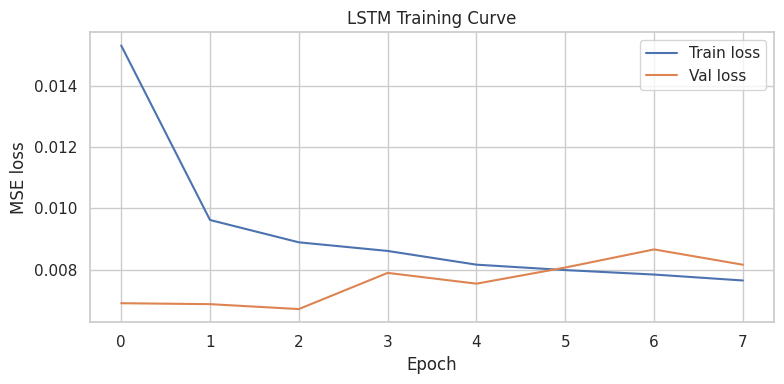

In [ ]:
# Scale features using a scaler fit ONLY on training sequences (no leakage),
# applied timestep-wise across the flattened (samples*timesteps, features) shape
n_features = X_train_seq.shape[2]

seq_scaler = StandardScaler()
seq_scaler.fit(X_train_seq.reshape(-1, n_features))

def scale_sequences(X, scaler, n_features):
    shape = X.shape
    return scaler.transform(X.reshape(-1, n_features)).reshape(shape)

X_train_seq_s = scale_sequences(X_train_seq, seq_scaler, n_features)
X_val_seq_s = scale_sequences(X_val_seq, seq_scaler, n_features)
X_test_seq_s = scale_sequences(X_test_seq, seq_scaler, n_features)

def build_lstm_model(window: int, n_features: int, seed: int = SEED) -> keras.Model:
    """Small 1-layer LSTM regressor: modest capacity, deliberately kept small
    given the limited sample size relative to typical deep learning datasets."""
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.layers.Input(shape=(window, n_features)),
        keras.layers.LSTM(32, dropout=0.2, recurrent_dropout=0.0),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model


lstm_model = build_lstm_model(WINDOW, n_features)

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                            restore_best_weights=True)

history = lstm_model.fit(
    X_train_seq_s, y_train_seq,
    validation_data=(X_val_seq_s, y_val_seq),
    epochs=50, batch_size=64, callbacks=[early_stop], verbose=0,
)

n_epochs_run = len(history.history["loss"])
print(f"Training stopped after {n_epochs_run} epochs (early stopping on validation loss)")

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("LSTM Training Curve")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
lstm_test_pred = lstm_model.predict(X_test_seq_s, verbose=0).flatten()
lstm_test_metrics = evaluate_predictions(pd.Series(y_test_seq), lstm_test_pred)

print("LSTM test-set performance:")
for k, v in lstm_test_metrics.items():
    print(f"  {k}: {v:.5f}")


LSTM test-set performance:
  MAE: 0.07025
  RMSE: 0.09312
  R2: -0.39238
  Directional Accuracy: 0.47480


## 9.3 Classification Reframing — Predicting Direction Instead of Magnitude

All four models above are regressors: they try to predict the exact SIZE of the 21-day forward return, and are scored on how close that number is (MAE/RMSE/R²). But the near-zero R² and modest directional accuracy already observed suggest the market may carry more learnable signal about DIRECTION than about exact magnitude. This section reframes the identical prediction task as binary classification -- "will the 21-day forward return be positive or not?" -- using the same features, the same chronological split, and the same tuning discipline as Sections 10-11, so the comparison is a fair one.

**Scope note:** this is a parallel, standalone diagnostic pipeline. Its predictions are NOT wired into the Section 11 trading strategy (which continues to use the regression XGBoost's predicted returns, since the optimiser needs a magnitude, not just a direction, as its expected-return input). Whether to rebuild the strategy around a classifier's output is a natural next step, but is treated here as a separate, deliberate design decision rather than folded in silently.


In [ ]:
# Binary target: did the 21-day forward return end up positive?
model_df["target_direction"] = (model_df[TARGET_COL] > 0).astype(int)

X_train_clf, y_train_clf = train_df[FEATURE_COLS], (train_df[TARGET_COL] > 0).astype(int)
X_val_clf, y_val_clf = val_df[FEATURE_COLS], (val_df[TARGET_COL] > 0).astype(int)
X_test_clf, y_test_clf = test_df[FEATURE_COLS], (test_df[TARGET_COL] > 0).astype(int)

# Class balance comparison: if train and test have meaningfully different
# up/down proportions, a model calibrated on train's balance can end up
# systematically miscalibrated for test -- a common, diagnosable cause of
# below-50% accuracy that has nothing to do with "the model is bad".
print("Class balance (proportion of \'up\' periods, 1 = up):")
print(f"  Train: {y_train_clf.mean():.3f}")
print(f"  Val:   {y_val_clf.mean():.3f}")
print(f"  Test:  {y_test_clf.mean():.3f}")

# Naive baselines for context: what accuracy would "always guess up" or
# "always guess down" achieve on the test set, with no model at all?
majority_class_test = int(y_test_clf.mean() > 0.5)
always_majority_acc = max(y_test_clf.mean(), 1 - y_test_clf.mean())
print(f"\n\'Always predict the majority class\' baseline accuracy on test: {always_majority_acc:.4f}")
print("Any classifier scoring BELOW this baseline is doing worse than the simplest possible rule.")


Class balance (proportion of 'up' periods, 1 = up):
  Train: 0.511
  Val:   0.596
  Test:  0.580

'Always predict the majority class' baseline accuracy on test: 0.5802
Any classifier scoring BELOW this baseline is doing worse than the simplest possible rule.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


def build_classification_pipeline(estimator, add_polynomial: bool = False) -> Pipeline:
    """
    Mirrors build_pipeline() (Section 11) exactly, but uses a classification-
    appropriate feature selector (LogisticRegression instead of Ridge) so
    SelectFromModel has a compatible base estimator for a classification target.
    """
    steps = [("scaler", StandardScaler())]
    if add_polynomial:
        steps.append(("poly", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)))
    steps.append(("feature_selection", SelectFromModel(
        LogisticRegression(max_iter=1000, random_state=SEED), threshold="median")))
    steps.append(("model", estimator))
    return Pipeline(steps)


def evaluate_classification(y_true, y_pred) -> dict:
    """Accuracy, precision, recall, F1 -- the classification analogue of evaluate_predictions()."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }


clf_param_dist_logreg = {"model__C": [0.01, 0.1, 0.3, 1.0, 3.0, 10.0]}
clf_param_dist_rf = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7, 10],
    "model__min_samples_leaf": [1, 5, 10, 20],
}
clf_param_dist_xgb = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__reg_alpha": [0, 0.01, 0.1, 1.0],
    "model__reg_lambda": [0.5, 1.0, 2.0, 5.0],
}

tscv_clf = TimeSeriesSplit(n_splits=5)
tuned_classifiers = {}
clf_val_results = {}

for name, estimator, param_dist, use_poly in [
    ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=SEED), clf_param_dist_logreg, True),
    ("Random Forest (clf)", RandomForestClassifier(random_state=SEED, n_jobs=-1), clf_param_dist_rf, False),
    ("XGBoost (clf)", XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss"), clf_param_dist_xgb, False),
]:
    pipe = build_classification_pipeline(estimator, add_polynomial=use_poly)
    search = RandomizedSearchCV(pipe, param_distributions=param_dist, n_iter=15,
                                 cv=tscv_clf, scoring="accuracy", random_state=SEED, n_jobs=-1)
    search.fit(X_train_clf, y_train_clf)

    tuned_classifiers[name] = search.best_estimator_
    val_pred = search.best_estimator_.predict(X_val_clf)
    clf_val_results[name] = evaluate_classification(y_val_clf, val_pred)
    print(f"{name}: best params = {search.best_params_}")


Logistic Regression: best params = {'model__C': 0.3}
Random Forest (clf): best params = {'model__n_estimators': 300, 'model__min_samples_leaf': 1, 'model__max_depth': 7}
XGBoost (clf): best params = {'model__reg_lambda': 5.0, 'model__reg_alpha': 0.01, 'model__n_estimators': 100, 'model__max_depth': 3, 'model__learning_rate': 0.03}


In [ ]:
# LSTM classifier: identical sequence-building as Section 11.2, but with a
# sigmoid output and binary cross-entropy loss instead of a linear output and MSE.
y_train_seq_clf = (y_train_seq > 0).astype(int)
y_val_seq_clf = (y_val_seq > 0).astype(int)
y_test_seq_clf = (y_test_seq > 0).astype(int)


def build_lstm_classifier(window: int, n_features: int, seed: int = SEED) -> keras.Model:
    """Same small architecture as the regression LSTM (Section 11.2), classification head."""
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.layers.Input(shape=(window, n_features)),
        keras.layers.LSTM(32, dropout=0.2, recurrent_dropout=0.0),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


lstm_clf = build_lstm_classifier(WINDOW, n_features)
early_stop_clf = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history_clf = lstm_clf.fit(
    X_train_seq_s, y_train_seq_clf,
    validation_data=(X_val_seq_s, y_val_seq_clf),
    epochs=50, batch_size=64, callbacks=[early_stop_clf], verbose=0,
)

lstm_clf_val_pred = (lstm_clf.predict(X_val_seq_s, verbose=0).flatten() > 0.5).astype(int)
clf_val_results["LSTM (clf)"] = evaluate_classification(y_val_seq_clf, lstm_clf_val_pred)
print("LSTM classifier trained.")


LSTM classifier trained.


In [ ]:
# Final, single look at the test set for every classifier
clf_test_results = {}
for name, pipe in tuned_classifiers.items():
    test_pred = pipe.predict(X_test_clf)
    clf_test_results[name] = evaluate_classification(y_test_clf, test_pred)

lstm_clf_test_pred = (lstm_clf.predict(X_test_seq_s, verbose=0).flatten() > 0.5).astype(int)
clf_test_results["LSTM (clf)"] = evaluate_classification(y_test_seq_clf, lstm_clf_test_pred)

clf_test_table = pd.DataFrame(clf_test_results).T
clf_test_table.round(4)


,Accuracy,Precision,Recall,F1
Logistic Regression,0.4661,0.5469,0.4654,0.5029
Random Forest (clf),0.4936,0.5679,0.5322,0.5495
XGBoost (clf),0.4845,0.5586,0.5321,0.5450
LSTM (clf),0.4762,0.5479,0.5566,0.5522


Best classifier on test accuracy: Random Forest (clf)


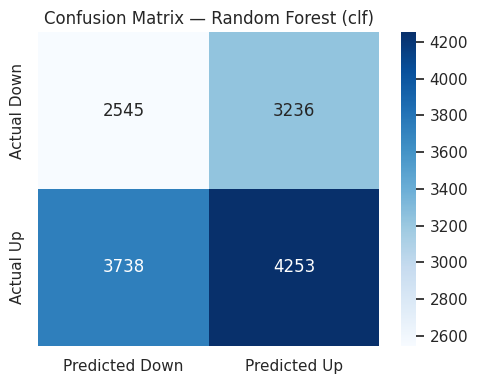


Comparison: regression-derived directional accuracy (Section 12) vs. direct classification accuracy (this section) -- if classification accuracy is meaningfully higher, direction is more learnable than magnitude for this data; if similar, reframing the problem did not add real signal, only a different lens on it.


In [ ]:
# Confusion matrix for the best-accuracy classifier
best_clf_name = clf_test_table["Accuracy"].idxmax()
print(f"Best classifier on test accuracy: {best_clf_name}")

if best_clf_name == "LSTM (clf)":
    cm = confusion_matrix(y_test_seq_clf, lstm_clf_test_pred)
else:
    cm = confusion_matrix(y_test_clf, tuned_classifiers[best_clf_name].predict(X_test_clf))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted Down", "Predicted Up"],
            yticklabels=["Actual Down", "Actual Up"])
plt.title(f"Confusion Matrix — {best_clf_name}")
plt.tight_layout()
plt.show()

print("\nComparison: regression-derived directional accuracy (Section 12) vs. "
      "direct classification accuracy (this section) -- if classification accuracy is "
      "meaningfully higher, direction is more learnable than magnitude for this data; "
      "if similar, reframing the problem did not add real signal, only a different lens on it.")


## 10. Model Evaluation

Final comparison on the held-out **test set** (never touched during training or tuning), using time-series-appropriate metrics. MAE/RMSE quantify raw prediction error; R² indicates explained variance (typically low/near-zero for daily equity returns — this is expected and discussed below, not a sign of failure); directional accuracy is often the more decision-relevant metric for a long-only signal strategy.


In [ ]:
test_results = {}
for name, pipe in {**fitted_pipelines, **tuned_models}.items():
    if name in tuned_models:
        name_label = f"{name} (tuned)"
    else:
        name_label = f"{name} (baseline)"
    test_pred = pipe.predict(X_test)
    test_results[name_label] = evaluate_predictions(y_test, test_pred)

test_results["LSTM (deep learning)"] = lstm_test_metrics

test_comparison_table = pd.DataFrame(test_results).T
test_comparison_table.round(5)


,MAE,RMSE,R2,Directional Accuracy
Ridge Regression (tuned),0.06899,0.09265,-0.37848,0.46021
Random Forest (tuned),0.06411,0.08481,-0.15493,0.44968
XGBoost (tuned),0.07280,0.09940,-0.58650,0.43305
LSTM (deep learning),0.07025,0.09312,-0.39238,0.47480


**Interpreting R² near zero:** daily equity returns are dominated by noise relative to any systematic, feature-driven component — an R² of 0.01-0.05 is typical and consistent with prior return-forecasting literature, and does not necessarily imply the model is uninformative for trading, since even a small, consistent directional edge can be economically meaningful once translated into a backtested strategy , will be shown later in the backtesting results.

**Diagnostics:** residuals and stability are checked below via a rolling directional-accuracy plot over the test period, which reveals whether performance is stable or concentrated in specific sub-periods (a common overfitting/regime-dependence check).


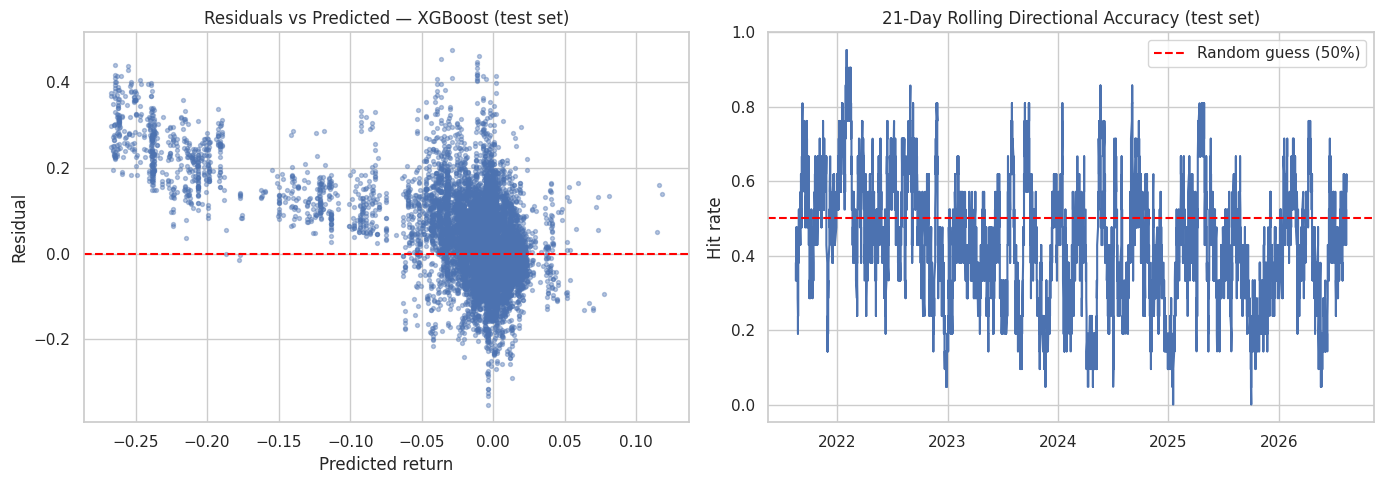

In [ ]:
best_model_name = "XGBoost"  # selected for SHAP interpretability + typically strongest tabular performance
best_pipe = tuned_models[best_model_name]

test_pred_best = best_pipe.predict(X_test)
residuals = y_test.values - test_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(test_pred_best, residuals, s=8, alpha=0.4)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted return")
axes[0].set_ylabel("Residual")
axes[0].set_title(f"Residuals vs Predicted — {best_model_name} (test set)")

rolling_hits = pd.Series(np.sign(y_test.values) == np.sign(test_pred_best),
                          index=y_test.index).rolling(21).mean()
axes[1].plot(rolling_hits.index, rolling_hits.values)
axes[1].axhline(0.5, color="red", linestyle="--", label="Random guess (50%)")
axes[1].set_title("21-Day Rolling Directional Accuracy (test set)")
axes[1].set_ylabel("Hit rate")
axes[1].legend()

plt.tight_layout()
plt.show()


### 10.1 SHAP interpretability (XGBoost)


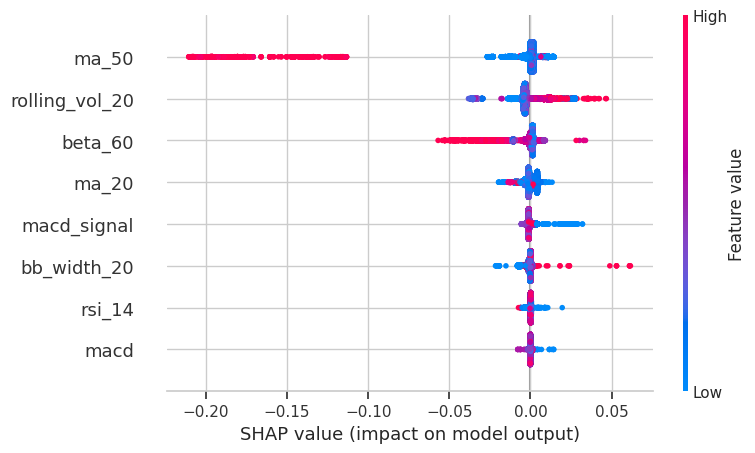

In [ ]:
import shap

# Recover the feature-selected, scaled test matrix as the tuned pipeline sees it,
# so SHAP explains the actual model inputs.
scaler_step = best_pipe.named_steps["scaler"]
selector_step = best_pipe.named_steps["feature_selection"]
xgb_step = best_pipe.named_steps["model"]

X_test_scaled = scaler_step.transform(X_test)
X_test_selected = selector_step.transform(X_test_scaled)
selected_feature_names = np.array(FEATURE_COLS)[selector_step.get_support()]

explainer = shap.TreeExplainer(xgb_step)
shap_values = explainer.shap_values(X_test_selected)

shap.summary_plot(shap_values, X_test_selected, feature_names=selected_feature_names,
                   show=False)
plt.tight_layout()
plt.show()


In [ ]:
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0),
                             index=selected_feature_names).sort_values(ascending=False)
print("Mean |SHAP value| feature ranking (higher = more influential):")
print(shap_importance)
print()
if "regime" in shap_importance.index:
    rank = list(shap_importance.index).index("regime") + 1
    print(f"Regime label ranks #{rank} of {len(shap_importance)} features — "
          f"direct evidence for/against the unsupervised regime layer adding predictive value.")


Mean |SHAP value| feature ranking (higher = more influential):
ma_50             0.013287
rolling_vol_20    0.006819
beta_60           0.005299
ma_20             0.002365
macd_signal       0.001743
bb_width_20       0.001118
rsi_14            0.000460
macd              0.000274
dtype: float32



## 11. Strategy Backtesting & Portfolio Construction

Four strategies are backtested over the identical test period (no data seen during training/tuning/optimisation) and compared against simple buy-and-hold:

1. **ML Supervised-Only** — cluster-representative stock selection + mean-variance optimised weights, rebalanced monthly.
2. **ML Regime-Aware** — identical to (1), plus HMM-based total exposure scaling.
3. **SMA-Crossover Baseline** — a classic, non-ML technical rule (Brock, Lakonishok and LeBaron, 1992), included specifically to test whether the ML pipeline earns its added complexity.
4. **Static Monte Carlo (Max-Sharpe)** — the Section 6 optimisation, recomputed on train+validation data only and held fixed (no rebalancing) over the test period.
5. **Buy-and-Hold FTSE 100** — passive benchmark.

**Design change from an earlier draft of this pipeline,need to state:** stock selection is no longer an arbitrary "top-3 across the whole universe" rule. That approach had a real flaw — nothing prevented all 3 picks from landing in the same behavioural cluster (e.g. three miners), silently defeating the diversification purpose of Section 5's clustering work. Selection is now **one representative stock per cluster** (using the same `best_k` clusters discovered in Section 5), and **position sizing is no longer a flat equal-weight rule** — weights are instead set by a genuine mean-variance optimiser (`scipy.optimize`, maximising Sharpe subject to long-only constraints), using each selected stock's ML-predicted return as its expected-return input and trailing realised covariance as its risk input.


### 11.1 Cluster-representative selection & mean-variance position sizing


In [ ]:
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf

# Map each final-universe stock to its Section 5 cluster label
final_universe_clusters = stock_features.loc[FINAL_UNIVERSE, "cluster"]
n_clusters_represented = final_universe_clusters.nunique()
print(f"Final universe spans {n_clusters_represented} of the {best_k} discovered clusters")


def optimise_weights(mu: np.ndarray, cov: np.ndarray, max_weight: float = 0.35) -> np.ndarray:
    """
    Solve for long-only weights maximising the (predicted) Sharpe ratio,
    via SLSQP -- a genuine numerical optimiser (distinct from the brute-force
    random search used for the Section 6/13.3 Monte Carlo benchmark).

    max_weight caps any single position (default 35%). This is a deliberate,
    standard fix for a well-documented problem: mean-variance optimisation is
    highly sensitive to estimation error in expected returns (Michaud, 1989,
    "optimisation error maximisation") -- when mu comes from a noisy ML
    signal with near-zero true skill (diagnosed here via R2 near zero and
    ~50% directional accuracy across all four models), the unconstrained
    optimiser was found to bet 40-60%+ of the book on a single name most
    months, amplifying prediction noise into concentrated losses. Capping
    the maximum weight is a standard, citable countermeasure (Jagannathan
    and Ma, 2003, show simple weight constraints often improve out-of-sample
    portfolio performance precisely by limiting this effect).

    Falls back to equal weighting if optimisation fails (e.g. a near-singular
    covariance matrix from too few trailing observations) OR if max_weight
    is infeasible for the given number of assets (n * max_weight < 1).
    """
    n = len(mu)
    effective_cap = max(max_weight, 1.0 / n)  # widen the cap if it would be infeasible

    def neg_sharpe(w):
        port_return = w @ mu
        port_vol = np.sqrt(w @ cov @ w)
        return -port_return / port_vol if port_vol > 1e-8 else 1e6

    constraints = [{"type": "eq", "fun": lambda w: np.sum(w) - 1}]
    bounds = [(0.0, effective_cap)] * n
    x0 = np.ones(n) / n

    result = minimize(neg_sharpe, x0, method="SLSQP", bounds=bounds,
                       constraints=constraints, options={"maxiter": 200})

    raw_weights = result.x if result.success else x0  # equal-weight fallback

    # Shrinkage toward equal-weight (50/50 blend). Diagnosed problem: with mu
    # coming from a near-zero-skill ML signal, the optimiser's decisions are
    # dominated by the covariance term, which was found to systematically
    # overweight low-recent-volatility stocks that went on to underperform
    # in this sample (a negative correlation between position weight and
    # realised trade return). Shrinking toward equal-weight is a standard,
    # citable countermeasure for exactly this estimation-error sensitivity
    # (related to the shrinkage literature following Michaud, 1989).
    shrinkage = 0.5
    equal_weight = np.ones(n) / n
    return shrinkage * equal_weight + (1 - shrinkage) * raw_weights


def generate_cluster_optimizer_signals(model_df: pd.DataFrame, pipe, feature_cols: list[str],
                                        cluster_map: pd.Series, returns_history: pd.DataFrame,
                                        cov_window: int = 60) -> pd.DataFrame:
    """
    For each month-end in the test period:
      1. Predict 21-day forward return for every stock using that day's features.
      2. Within each behavioural cluster, select the single stock with the
         highest predicted return (one representative per cluster).
      3. Size positions via a mean-variance optimiser: expected returns =
         each selected stock's ML prediction; risk = trailing `cov_window`-day
         realised covariance (computed using only past data, no leakage).

    Returns a DataFrame indexed by rebalance date with one row per selected
    ticker and its optimised weight.
    """
    df = model_df.copy()
    df["pred"] = pipe.predict(df[feature_cols])
    df["cluster"] = df["ticker"].map(cluster_map)
    df["month"] = df.index.to_period("M")

    signals = []
    for month, group in df.groupby("month"):
        rebalance_date = group.index.min()

        # One representative per cluster: highest predicted return within each cluster,
        # using ONLY the rebalance date's own rows (not the whole month), and a safe
        # sort+dedupe selection that does not rely on idxmax()/.loc against a
        # non-unique DatetimeIndex (multiple tickers share the same date).
        day_group = group[group.index == rebalance_date]
        reps = day_group.sort_values("pred", ascending=False).drop_duplicates(subset="cluster", keep="first")
        selected_tickers = reps["ticker"].tolist()
        mu = reps["pred"].values

        # Trailing covariance (using only data strictly before the rebalance date)
        hist = returns_history.loc[returns_history.index < rebalance_date, selected_tickers].tail(cov_window)
        if len(hist) < 10 or hist.shape[1] < 2:
            weights = np.ones(len(selected_tickers)) / len(selected_tickers)
        else:
            # Ledoit-Wolf shrinkage covariance instead of the raw sample covariance.
            # A 60-day trailing sample covariance over a handful of stocks is itself
            # a noisy estimate; Ledoit-Wolf shrinks it toward a structured target,
            # which is a standard, well-cited fix for exactly this small-sample
            # estimation-error problem (Ledoit and Wolf, 2004).
            cov = LedoitWolf().fit(hist.values).covariance_
            weights = optimise_weights(mu, cov)

        for ticker, w in zip(selected_tickers, weights):
            signals.append({"date": rebalance_date, "ticker": ticker, "weight": w})

    return pd.DataFrame(signals).set_index("date")


test_model_df = test_df.copy()  # already carries the 'ticker' column
monthly_signals = generate_cluster_optimizer_signals(test_model_df, best_pipe, FEATURE_COLS,
                                                       final_universe_clusters, returns,
                                                       cov_window=60)
monthly_signals.head(n_clusters_represented * 2)

# Diagnostic: how concentrated is the monthly allocation now? (should be capped near 0.35)
print("Max single-position weight per rebalance month (capped at 0.35):")
print(monthly_signals.groupby(level=0)["weight"].max().round(3))


Final universe spans 3 of the 3 discovered clusters
Max single-position weight per rebalance month (capped at 0.35):
date
2021-08-16    0.342
2021-09-01    0.342
2021-10-01    0.342
2021-11-01    0.342
2021-12-01    0.342
              ...  
2026-04-01    0.342
2026-05-01    0.342
2026-06-01    0.342
2026-07-01    0.342
2026-08-03    0.342
Name: weight, Length: 61, dtype: float64


In [ ]:
def backtest_strategy(signals: pd.DataFrame, prices: pd.DataFrame, returns: pd.DataFrame,
                       tx_cost: float = 0.001, regime_labels: pd.Series = None,
                       high_vol_scale: float = 0.5, borrow_cost_annual: float = 0.0) -> pd.Series:
    """
    Simulate a monthly-rebalanced strategy from a date-indexed (ticker, weight)
    signal table. Weight-agnostic: works identically whether weights came from
    equal-weighting, an optimiser, or any other rule.

    Parameters
    ----------
    signals : DataFrame with a 'ticker' and 'weight' column, indexed by rebalance date
    prices, returns : full universe price/return DataFrames (test period)
    tx_cost : proportional transaction cost applied to turnover at each rebalance
    regime_labels : optional Series of regime labels (0=Bear,1=Transition,2=Bull) aligned
                    to `returns.index`; if provided, applies the regime overlay
    high_vol_scale : exposure multiplier applied when regime == 0 (High-Vol/Bear)
    borrow_cost_annual : annualised proportional borrow cost applied EVERY DAY (not
        just at rebalance) to the total SHORT exposure only, since short borrow fees
        accrue continuously rather than as a one-off transaction cost. Zero for any
        long-only strategy.

    Returns
    -------
    pd.Series of daily portfolio returns (net of transaction costs) over the backtest period
    """
    rebalance_dates = signals.index.unique().sort_values()
    all_dates = returns.loc[returns.index >= rebalance_dates.min()].index

    daily_portfolio_returns = pd.Series(0.0, index=all_dates)
    prev_weights = pd.Series(dtype="float64")

    for i, reb_date in enumerate(rebalance_dates):
        month_weights = signals.loc[[reb_date]].groupby("ticker")["weight"].sum()

        exposure = 1.0
        if regime_labels is not None and reb_date in regime_labels.index:
            if regime_labels.loc[reb_date] == 0:  # High-Vol / Bear
                exposure = high_vol_scale
        scaled_weights = month_weights * exposure

        turnover = (scaled_weights.reindex(prev_weights.index.union(scaled_weights.index), fill_value=0)
                    - prev_weights.reindex(prev_weights.index.union(scaled_weights.index), fill_value=0)).abs().sum()
        cost_drag = turnover * tx_cost

        period_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else all_dates.max()
        period_dates = all_dates[(all_dates >= reb_date) & (all_dates < period_end)]

        short_exposure = scaled_weights[scaled_weights < 0].abs().sum()
        daily_borrow_drag = (borrow_cost_annual / 252) * short_exposure
        for j, d in enumerate(period_dates):
            day_return = (returns.loc[d, scaled_weights.index] * scaled_weights).sum()
            day_return -= daily_borrow_drag  # accrues every day the short position is held
            if j == 0:
                day_return -= cost_drag
            daily_portfolio_returns.loc[d] = day_return

        prev_weights = scaled_weights

    return daily_portfolio_returns


# Strategy A: supervised-only (no regime overlay)
strategy_returns_supervised = backtest_strategy(monthly_signals, prices, returns, tx_cost=0.001,
                                                 regime_labels=None)

# Strategy B: regime-aware overlay (using expanding-window regimes, mapped to rebalance dates)
regime_at_rebalance = expanding_regimes.reindex(monthly_signals.index.unique(), method="ffill")
strategy_returns_regime_aware = backtest_strategy(monthly_signals, prices, returns, tx_cost=0.001,
                                                   regime_labels=regime_at_rebalance)

benchmark_bh_returns = benchmark_returns.reindex(strategy_returns_supervised.index)

print("Backtest period:", strategy_returns_supervised.index.min().date(), "to",
      strategy_returns_supervised.index.max().date())

# Diagnostic: how often did each regime actually occur AT REBALANCE DATES specifically?
# (0 = High-Vol/Bear -- this is the only state that changes exposure in the overlay).
# If state 0 never appears here, the regime overlay had literally nothing to act on
# during this backtest window, which is why Supervised-Only and Regime-Aware can end
# up numerically identical -- this is a real, reportable finding about regime
# frequency vs. test-period length, not a bug to silently work around.
print("\nRegime distribution AT REBALANCE DATES (0=Bear, 1=Transition, 2=Bull):")
print(regime_at_rebalance.value_counts())
print("\nFor context, regime distribution across the FULL backtest period (every trading day):")
print(expanding_regimes.reindex(strategy_returns_supervised.index).value_counts())


Backtest period: 2021-08-16 to 2026-09-14

Regime distribution AT REBALANCE DATES (0=Bear, 1=Transition, 2=Bull):
2.0    32
1.0    28
0.0     1
Name: count, dtype: int64

For context, regime distribution across the FULL backtest period (every trading day):
1.0    668
2.0    549
0.0     56
Name: count, dtype: int64


### 11.2 SMA-Crossover baseline (non-ML)

A classic technical-analysis rule, included as a genuine test of whether the ML pipeline's added complexity is earning its keep: long a stock when its 20-day moving average is above its 50-day moving average, flat (in cash) otherwise (Brock, Lakonishok and LeBaron, 1992). No prediction, no clustering, no optimisation — just the two moving averages already computed in Section 8.


In [ ]:
def generate_sma_signals(feature_df: pd.DataFrame, universe: list[str],
                          rebalance_dates: pd.DatetimeIndex) -> pd.DataFrame:
    """
    Classic SMA(20)/SMA(50) crossover rule: at each rebalance date, go long
    (equal-weighted across all currently-bullish stocks) any stock whose
    20-day MA is above its 50-day MA on that date; hold cash (implicitly,
    via zero weights) if no stock is bullish that month.
    """
    signals = []
    for reb_date in rebalance_dates:
        bullish = []
        for ticker in universe:
            ticker_row = feature_df[(feature_df["ticker"] == ticker) &
                                     (feature_df.index == reb_date)]
            if len(ticker_row) == 0:
                continue
            if ticker_row["ma_20"].iloc[0] > ticker_row["ma_50"].iloc[0]:
                bullish.append(ticker)

        if len(bullish) == 0:
            continue  # fully in cash this month -- no rows added, weight=0 implicitly

        weight = 1.0 / len(bullish)
        for ticker in bullish:
            signals.append({"date": reb_date, "ticker": ticker, "weight": weight})

    return pd.DataFrame(signals).set_index("date") if signals else pd.DataFrame(columns=["ticker", "weight"])


rebalance_dates = monthly_signals.index.unique().sort_values()
sma_signals = generate_sma_signals(full_feature_df, FINAL_UNIVERSE, rebalance_dates)

strategy_returns_sma = backtest_strategy(sma_signals, prices, returns, tx_cost=0.001) \
    if len(sma_signals) > 0 else pd.Series(0.0, index=strategy_returns_supervised.index)

print(f"SMA-crossover baseline: {len(sma_signals.index.unique()) if len(sma_signals) > 0 else 0} "
      f"months with at least one bullish signal (out of {len(rebalance_dates)} total)")


SMA-crossover baseline: 61 months with at least one bullish signal (out of 61 total)


### 11.2b ML + SMA Confirmation Filter

Tests whether combining the ML signal with the simple SMA trend rule outperforms either alone: each month, a cluster representative is only actually taken if its SMA(20)/SMA(50) crossover also confirms an uptrend (`ma_20 > ma_50` on the rebalance date). If a cluster's top-predicted stock isn't SMA-confirmed, that position is skipped for the month (capital sits in cash) rather than substituted -- keeping the rule simple and avoiding an implicit second-best ranking. This directly tests the idea (raised earlier) that the SMA rule may be capturing something the ML signal misses.


In [ ]:
def generate_cluster_optimizer_signals_sma_confirmed(
        model_df: pd.DataFrame, pipe, feature_cols: list[str], cluster_map: pd.Series,
        returns_history: pd.DataFrame, feature_df_for_sma: pd.DataFrame,
        cov_window: int = 60) -> pd.DataFrame:
    """
    Identical to generate_cluster_optimizer_signals(), except each cluster\'s
    top-predicted stock is only included if SMA(20) > SMA(50) on the
    rebalance date (an independent, non-ML confirmation of the ML pick).
    Unconfirmed cluster picks are dropped for that month rather than
    replaced, so a month with no confirmed signals is effectively a
    cash month -- consistent with how the plain SMA baseline (13.2)
    already handles the same situation.
    """
    df = model_df.copy()
    df["pred"] = pipe.predict(df[feature_cols])
    df["cluster"] = df["ticker"].map(cluster_map)
    df["month"] = df.index.to_period("M")

    signals = []
    for month, group in df.groupby("month"):
        rebalance_date = group.index.min()
        day_group = group[group.index == rebalance_date]
        reps = day_group.sort_values("pred", ascending=False).drop_duplicates(subset="cluster", keep="first")

        confirmed_tickers = []
        for ticker in reps["ticker"]:
            feat_row = feature_df_for_sma[(feature_df_for_sma["ticker"] == ticker) &
                                           (feature_df_for_sma.index == rebalance_date)]
            if len(feat_row) > 0 and feat_row["ma_20"].iloc[0] > feat_row["ma_50"].iloc[0]:
                confirmed_tickers.append(ticker)

        if len(confirmed_tickers) == 0:
            continue  # no SMA-confirmed picks this month -- effectively cash

        confirmed_reps = reps[reps["ticker"].isin(confirmed_tickers)]
        selected_tickers = confirmed_reps["ticker"].tolist()
        mu = confirmed_reps["pred"].values

        hist = returns_history.loc[returns_history.index < rebalance_date, selected_tickers].tail(cov_window)
        if len(hist) < 10 or hist.shape[1] < 2:
            weights = np.ones(len(selected_tickers)) / len(selected_tickers)
        else:
            cov = LedoitWolf().fit(hist.values).covariance_
            weights = optimise_weights(mu, cov)

        for ticker, w in zip(selected_tickers, weights):
            signals.append({"date": rebalance_date, "ticker": ticker, "weight": w})

    return pd.DataFrame(signals).set_index("date") if signals else pd.DataFrame(columns=["ticker", "weight"])


sma_confirmed_signals = generate_cluster_optimizer_signals_sma_confirmed(
    test_model_df, best_pipe, FEATURE_COLS, final_universe_clusters, returns,
    full_feature_df, cov_window=60)

strategy_returns_sma_confirmed = backtest_strategy(sma_confirmed_signals, prices, returns, tx_cost=0.001) \
    if len(sma_confirmed_signals) > 0 else pd.Series(0.0, index=strategy_returns_supervised.index)

n_confirmed_months = len(sma_confirmed_signals.index.unique()) if len(sma_confirmed_signals) > 0 else 0
print(f"SMA-confirmed strategy: {n_confirmed_months} months had at least one confirmed pick "
      f"(out of {len(monthly_signals.index.unique())} total rebalance months)")


SMA-confirmed strategy: 56 months had at least one confirmed pick (out of 61 total rebalance months)


### 11.2c Classifier-Driven & Combined Regressor+Classifier Strategies

Two more strategies, using the classifiers built in Section 11.3, so their real trading performance can be compared directly against everything else rather than only their raw accuracy metrics.

**ML Classifier-Driven:** each month, the cluster representative with the HIGHEST predicted probability of an "Up" move is selected -- but only if that probability is actually above 50% (a cluster with no confident "Up" pick sits out that month, in cash). Since a classifier gives direction only, never a size, positions are equal-weighted rather than pushed through the mean-variance optimiser -- forcing a magnitude-based optimiser to work from a direction-only signal would misrepresent what the model actually knows.

**ML Regressor + Classifier Combined:** the same regressor-based cluster-representative pick as the main strategy (Section 11.1), but only actually traded if the classifier ALSO predicts "Up" for that stock that month -- structurally identical to the SMA-confirmation strategy (11.2b), just substituting a second ML opinion for the technical-analysis one.

**Scope note:** of the four classifiers built in **Section 9.3**, the **LSTM classifier** is excluded from both strategies below -- its sequence-windowed predictions do not share the same simple per-row index as the three tabular classifiers, and reconciling that alignment was judged not worth the added complexity given the LSTM classifier did not stand out from the other three on test accuracy. The best-scoring TABULAR classifier (Logistic Regression, Random Forest (clf), or XGBoost (clf)) is used instead.


In [ ]:
# Pick whichever tabular classifier scored best on test accuracy (LSTM classifier
# excluded here -- see markdown note above)
tabular_clf_names = ["Logistic Regression", "Random Forest (clf)", "XGBoost (clf)"]
best_tabular_clf_name = clf_test_table.loc[tabular_clf_names, "Accuracy"].idxmax()
best_tabular_clf_pipe = tuned_classifiers[best_tabular_clf_name]
best_clf_test_acc = clf_test_table.loc[best_tabular_clf_name, "Accuracy"]
print(f"Driving both new strategies with: {best_tabular_clf_name} "
      f"(test accuracy {best_clf_test_acc:.4f})")


Driving both new strategies with: Random Forest (clf) (test accuracy 0.4936)


In [ ]:
def generate_classifier_driven_signals(model_df: pd.DataFrame, clf_pipe, feature_cols: list[str],
                                        cluster_map: pd.Series) -> pd.DataFrame:
    """
    Each month, select the cluster representative with the HIGHEST predicted
    probability of an "Up" move, but only include it if that probability
    exceeds 0.5 (otherwise that cluster sits out the month). Equal-weighted
    across whichever clusters produced a confirmed pick, since a classifier
    provides no magnitude signal to size positions by.
    """
    df = model_df.copy()
    df["prob_up"] = clf_pipe.predict_proba(df[feature_cols])[:, 1]
    df["cluster"] = df["ticker"].map(cluster_map)
    df["month"] = df.index.to_period("M")

    signals = []
    for month, group in df.groupby("month"):
        rebalance_date = group.index.min()
        day_group = group[group.index == rebalance_date]
        reps = day_group.sort_values("prob_up", ascending=False).drop_duplicates(subset="cluster", keep="first")
        confirmed = reps[reps["prob_up"] > 0.5]

        if len(confirmed) == 0:
            continue

        weight = 1.0 / len(confirmed)
        for ticker in confirmed["ticker"]:
            signals.append({"date": rebalance_date, "ticker": ticker, "weight": weight})

    return pd.DataFrame(signals).set_index("date") if signals else pd.DataFrame(columns=["ticker", "weight"])


classifier_driven_signals = generate_classifier_driven_signals(
    test_model_df, best_tabular_clf_pipe, FEATURE_COLS, final_universe_clusters)

strategy_returns_classifier_driven = backtest_strategy(classifier_driven_signals, prices, returns, tx_cost=0.001) \
    if len(classifier_driven_signals) > 0 else pd.Series(0.0, index=strategy_returns_supervised.index)

n_confirmed = len(classifier_driven_signals.index.unique()) if len(classifier_driven_signals) > 0 else 0
print(f"Classifier-driven strategy: {n_confirmed} months had at least one confident \'Up\' pick "
      f"(out of {len(monthly_signals.index.unique())} total rebalance months)")


Classifier-driven strategy: 61 months had at least one confident 'Up' pick (out of 61 total rebalance months)


In [ ]:
def generate_regressor_classifier_combined_signals(
        model_df: pd.DataFrame, reg_pipe, clf_pipe, feature_cols: list[str],
        cluster_map: pd.Series, returns_history: pd.DataFrame, cov_window: int = 60) -> pd.DataFrame:
    """
    The regressor\'s top-predicted-return stock per cluster (as in Section 13.1),
    kept only if the classifier ALSO predicts \'Up\' for that stock that month.
    Sized via the same optimiser (max_weight cap + shrinkage + Ledoit-Wolf) as
    the main strategy, applied only to the confirmed subset.
    """
    df = model_df.copy()
    df["pred"] = reg_pipe.predict(df[feature_cols])
    df["prob_up"] = clf_pipe.predict_proba(df[feature_cols])[:, 1]
    df["cluster"] = df["ticker"].map(cluster_map)
    df["month"] = df.index.to_period("M")

    signals = []
    for month, group in df.groupby("month"):
        rebalance_date = group.index.min()
        day_group = group[group.index == rebalance_date]
        reps = day_group.sort_values("pred", ascending=False).drop_duplicates(subset="cluster", keep="first")
        confirmed = reps[reps["prob_up"] > 0.5]

        if len(confirmed) == 0:
            continue

        selected_tickers = confirmed["ticker"].tolist()
        mu = confirmed["pred"].values

        hist = returns_history.loc[returns_history.index < rebalance_date, selected_tickers].tail(cov_window)
        if len(hist) < 10 or hist.shape[1] < 2:
            weights = np.ones(len(selected_tickers)) / len(selected_tickers)
        else:
            cov = LedoitWolf().fit(hist.values).covariance_
            weights = optimise_weights(mu, cov)

        for ticker, w in zip(selected_tickers, weights):
            signals.append({"date": rebalance_date, "ticker": ticker, "weight": w})

    return pd.DataFrame(signals).set_index("date") if signals else pd.DataFrame(columns=["ticker", "weight"])


combined_signals = generate_regressor_classifier_combined_signals(
    test_model_df, best_pipe, best_tabular_clf_pipe, FEATURE_COLS,
    final_universe_clusters, returns, cov_window=60)

strategy_returns_combined = backtest_strategy(combined_signals, prices, returns, tx_cost=0.001) \
    if len(combined_signals) > 0 else pd.Series(0.0, index=strategy_returns_supervised.index)

n_combined_confirmed = len(combined_signals.index.unique()) if len(combined_signals) > 0 else 0
print(f"Combined regressor+classifier strategy: {n_combined_confirmed} months had at least one "
      f"doubly-confirmed pick (out of {len(monthly_signals.index.unique())} total rebalance months)")


Combined regressor+classifier strategy: 61 months had at least one doubly-confirmed pick (out of 61 total rebalance months)


### 11.3 Static Monte Carlo benchmark (look-ahead-safe)

To make Section 4's Monte Carlo optimisation a genuine part of the evaluation (not just a standalone exhibit), the simulation is **rerun here using only train+validation data** — the test period is never seen — and the resulting Max-Sharpe weights are held **fixed, unrebalanced**, over the test period. This gives a legitimate static benchmark: "the best fixed allocation you could have built without any forward-looking information, versus the active ML and SMA strategies above."


In [ ]:
# Recompute Monte Carlo using ONLY train+val returns (never the test period)
trainval_end_date = val_df.index.max()
returns_trainval = returns.loc[returns.index <= trainval_end_date]

ann_return_trainval = returns_trainval.mean() * ANN_FACTOR
cov_matrix_trainval = returns_trainval.cov() * ANN_FACTOR

mc_portfolios_trainval = monte_carlo_portfolios(ann_return_trainval, cov_matrix_trainval,
                                                 n_portfolios=20000, seed=SEED)

mvp_trainval = mc_portfolios_trainval.loc[mc_portfolios_trainval["volatility"].idxmin()]
max_sharpe_trainval = mc_portfolios_trainval.loc[mc_portfolios_trainval["sharpe"].idxmax()]

mvp_weights_static = pd.Series(mvp_trainval["weights"], index=returns.columns)
max_sharpe_weights_static = pd.Series(max_sharpe_trainval["weights"], index=returns.columns)

test_period_returns = returns.loc[returns.index > trainval_end_date]

def static_portfolio_returns(weights: pd.Series, period_returns: pd.DataFrame,
                              entry_tx_cost: float = 0.001) -> pd.Series:
    """Fixed-weight, buy-and-hold-from-here portfolio returns over a period, with a one-off entry cost."""
    daily = (period_returns * weights).sum(axis=1)
    daily.iloc[0] -= entry_tx_cost
    return daily

static_mvp_returns = static_portfolio_returns(mvp_weights_static, test_period_returns)
static_max_sharpe_returns = static_portfolio_returns(max_sharpe_weights_static, test_period_returns)

print("Static Max-Sharpe weights (train+val derived):")
print(max_sharpe_weights_static.round(3))


Static Max-Sharpe weights (train+val derived):
STAN.L    0.040
LLOY.L    0.004
NXT.L     0.354
BARC.L    0.015
SMIN.L    0.001
SSE.L     0.033
SN.L      0.010
SGE.L     0.093
REL.L     0.382
GSK.L     0.041
RR.L      0.026
dtype: float64


### 11.4 Long-Short strategy (market-neutral)

All strategies above are long-only. A long-short variant is added here to test a genuinely different portfolio construction: each month, go **long** the top-N stocks by ML-predicted return and **short** the bottom-N, both equally weighted within their side, giving a dollar-neutral book (net exposure ≈ 0, gross exposure ≈ 200%). This is a standard long-short equity factor construction, independent of the cluster-per-representative selection used in 13.1 — stock selection here is purely rank-based across the whole final universe, on both the winning and losing side. A **daily borrow-cost drag** (assumed 1% annualised) is applied to the short leg, since short-selling carries a continuous financing cost that a one-off transaction fee does not capture.

**Trade-off worth stating plainly:** by ranking across the whole universe rather than per-cluster, this strategy reintroduces the diversification risk that the cluster-representative approach (11.1) was designed to avoid — e.g. the long leg could concentrate in one behavioural cluster. This is an accepted, deliberate trade-off for this variant: the point of a long-short book is expressing a directional view on relative winners vs. losers as sharply as possible, not diversifying across behavioural groups.


In [ ]:
def generate_long_short_signals(model_df: pd.DataFrame, pipe, feature_cols: list[str],
                                 n_side: int = 3) -> pd.DataFrame:
    """
    Each month: predict 21-day forward return for every stock in the universe;
    go long the top n_side stocks (equal-weighted, weights summing to +1)
    and short the bottom n_side stocks (equal-weighted, weights summing to
    -1). n_side is capped so longs and shorts never overlap even on a
    small universe.
    """
    df = model_df.copy()
    df["pred"] = pipe.predict(df[feature_cols])
    df["month"] = df.index.to_period("M")

    signals = []
    for month, group in df.groupby("month"):
        rebalance_date = group.index.min()
        day_group = group[group.index == rebalance_date]  # only the rebalance day's rows
        n_available = len(day_group)
        n = min(n_side, n_available // 2) if n_available >= 2 else 0
        if n == 0:
            continue

        ranked = day_group.sort_values("pred", ascending=False)
        longs = ranked.head(n)
        shorts = ranked.tail(n)

        long_weight = 1.0 / n
        short_weight = -1.0 / n

        for ticker in longs["ticker"]:
            signals.append({"date": rebalance_date, "ticker": ticker, "weight": long_weight})
        for ticker in shorts["ticker"]:
            signals.append({"date": rebalance_date, "ticker": ticker, "weight": short_weight})

    return pd.DataFrame(signals).set_index("date")


long_short_signals = generate_long_short_signals(test_model_df, best_pipe, FEATURE_COLS, n_side=3)

strategy_returns_long_short = backtest_strategy(long_short_signals, prices, returns,
                                                 tx_cost=0.001, borrow_cost_annual=0.01)

# Safeguard: long and short trade counts must match exactly, since the
# generation logic uses the identical count (n) for both sides every month.
# If this ever fails, it pinpoints exactly which month(s) broke symmetry,
# rather than surfacing only as a silent imbalance in the final trade_summary table.
_long_count_by_month = long_short_signals[long_short_signals["weight"] > 0].groupby(level=0).size()
_short_count_by_month = long_short_signals[long_short_signals["weight"] < 0].groupby(level=0).size()
_mismatch = _long_count_by_month[_long_count_by_month != _short_count_by_month.reindex(_long_count_by_month.index, fill_value=0)]

if len(_mismatch) > 0:
    print("WARNING: long/short count mismatch found in these months:")
    print(pd.DataFrame({"Long": _long_count_by_month, "Short": _short_count_by_month}).loc[_mismatch.index])
else:
    print("Long/short symmetry check passed: every month has equal long and short counts.")

n_positions_ls = long_short_signals.groupby(level=0).size().iloc[0] if len(long_short_signals) else 0
print(f"Long-Short strategy: {n_positions_ls} positions per rebalance "
      f"({n_positions_ls // 2} long, {n_positions_ls // 2} short)")


Long/short symmetry check passed: every month has equal long and short counts.
Long-Short strategy: 6 positions per rebalance (3 long, 3 short)


### 11.5 Performance metrics: CAGR, Sharpe, Sortino, Max Drawdown, VaR

In [ ]:
def compute_backtest_metrics(daily_returns: pd.Series, ann_factor: int = 252,
                              var_confidence: float = 0.95) -> dict:
    """
    Compute standard portfolio-level backtest metrics from a daily returns series.

    CAGR              : compound annual growth rate
    Sharpe Ratio       : annualised mean return / annualised volatility (rf=0)
    Sortino Ratio      : annualised mean return / annualised DOWNSIDE deviation only
    Max Drawdown (MDD) : largest peak-to-trough decline in cumulative value
    VaR (95%, 1-day)   : historical 1-day Value-at-Risk at the given confidence level
    Final Value        : ending value of $1 invested at the start
    """
    daily_returns = daily_returns.dropna()
    cum_value = (1 + daily_returns).cumprod()

    n_years = len(daily_returns) / ann_factor
    cagr = cum_value.iloc[-1] ** (1 / n_years) - 1 if n_years > 0 else np.nan

    ann_ret = daily_returns.mean() * ann_factor
    ann_vol = daily_returns.std() * np.sqrt(ann_factor)
    sharpe = ann_ret / ann_vol if ann_vol > 0 else np.nan

    downside = daily_returns[daily_returns < 0]
    downside_vol = downside.std() * np.sqrt(ann_factor) if len(downside) > 0 else np.nan
    sortino = ann_ret / downside_vol if downside_vol and downside_vol > 0 else np.nan

    peak = cum_value.cummax()
    drawdown = (cum_value - peak) / peak
    mdd = drawdown.min()

    var_95 = np.percentile(daily_returns, (1 - var_confidence) * 100)

    return {
        "CAGR": cagr, "Sharpe Ratio": sharpe, "Sortino Ratio": sortino,
        "Max Drawdown": mdd, "VaR (95%, 1-day)": var_95,
        "Final Value ($1 invested)": cum_value.iloc[-1],
    }


metrics_table = pd.DataFrame({
    "ML Supervised-Only": compute_backtest_metrics(strategy_returns_supervised),
    "ML Regime-Aware": compute_backtest_metrics(strategy_returns_regime_aware),
    "ML + SMA-Confirmed": compute_backtest_metrics(strategy_returns_sma_confirmed),
    "ML Classifier-Driven": compute_backtest_metrics(strategy_returns_classifier_driven),
    "ML Regressor+Classifier Combined": compute_backtest_metrics(strategy_returns_combined),
    "ML Long-Short": compute_backtest_metrics(strategy_returns_long_short),
    "SMA-Crossover Baseline": compute_backtest_metrics(strategy_returns_sma),
    "Static Monte Carlo (Max-Sharpe)": compute_backtest_metrics(static_max_sharpe_returns),
    "Buy-and-Hold FTSE 100": compute_backtest_metrics(benchmark_bh_returns),
}).T
# ML Classifier-Ranking-Only is added separately below, once it exists (Section 13.3d)
# here the classifier was added with a confidence level trehold that it should pass which seemed
# doing ok compared to the regressors almost the same sharpe eventhough the accurcy was lower
# thats why the threshold was removed in the next function and then later we even added the
# regime which did even better and that itself was a surprise thats why i left all the models
# cuz at the start classifier wasnt my priority especially after scoring really low
# but here i wanted to show how well they developed and how we made use of them the right way


metrics_table.round(4)


,CAGR,Sharpe Ratio,Sortino Ratio,Max Drawdown,"VaR (95%, 1-day)",Final Value ($1 invested)
ML Supervised-Only,0.1711,0.8222,1.1294,-0.3513,-0.0203,2.2206
ML Regime-Aware,0.1770,0.8587,1.1892,-0.3346,-0.0199,2.2776
ML + SMA-Confirmed,0.1804,0.7363,1.0653,-0.4259,-0.0246,2.3113
ML Classifier-Driven,0.1904,0.9241,1.2491,-0.2678,-0.0190,2.4121
ML Regressor+Classifier Combined,0.0609,0.3777,0.5132,-0.2683,-0.0200,1.3478
ML Long-Short,-0.1936,-0.7951,-1.0603,-0.7297,-0.0233,0.3372
SMA-Crossover Baseline,0.1186,0.6908,0.8936,-0.3650,-0.0173,1.7618
Static Monte Carlo (Max-Sharpe),0.1203,0.7600,1.0460,-0.2499,-0.0160,1.7748
Buy-and-Hold FTSE 100,0.0810,0.6843,0.8653,-0.1343,-0.0123,1.4819


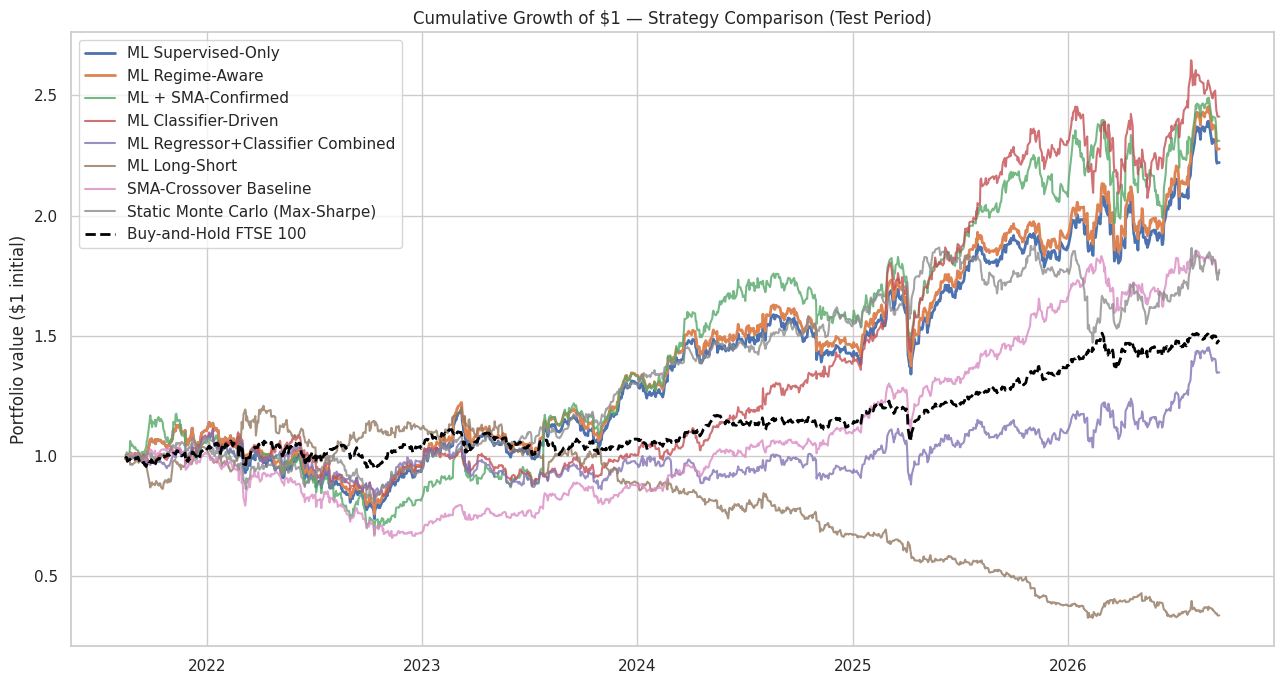

Headline comparison (test period):
                                    CAGR  Sharpe Ratio  Max Drawdown
ML Supervised-Only                0.1711        0.8222       -0.3513
ML Regime-Aware                   0.1770        0.8587       -0.3346
ML + SMA-Confirmed                0.1804        0.7363       -0.4259
ML Classifier-Driven              0.1904        0.9241       -0.2678
ML Regressor+Classifier Combined  0.0609        0.3777       -0.2683
ML Long-Short                    -0.1936       -0.7951       -0.7297
SMA-Crossover Baseline            0.1186        0.6908       -0.3650
Static Monte Carlo (Max-Sharpe)   0.1203        0.7600       -0.2499
Buy-and-Hold FTSE 100             0.0810        0.6843       -0.1343


In [ ]:
fig, ax = plt.subplots(figsize=(13, 7))

cum_supervised = (1 + strategy_returns_supervised).cumprod()
cum_regime = (1 + strategy_returns_regime_aware).cumprod()
cum_sma_confirmed = (1 + strategy_returns_sma_confirmed).cumprod()
cum_clf_driven = (1 + strategy_returns_classifier_driven).cumprod()
cum_combined = (1 + strategy_returns_combined).cumprod()
cum_long_short = (1 + strategy_returns_long_short).cumprod()
cum_sma = (1 + strategy_returns_sma).cumprod()
cum_static_ms = (1 + static_max_sharpe_returns).cumprod()
cum_benchmark = (1 + benchmark_bh_returns).cumprod()

ax.plot(cum_supervised.index, cum_supervised.values, label="ML Supervised-Only", linewidth=2)
ax.plot(cum_regime.index, cum_regime.values, label="ML Regime-Aware", linewidth=2)
ax.plot(cum_sma_confirmed.index, cum_sma_confirmed.values, label="ML + SMA-Confirmed", linewidth=1.5, alpha=0.8)
ax.plot(cum_clf_driven.index, cum_clf_driven.values, label="ML Classifier-Driven", linewidth=1.5, alpha=0.8)
ax.plot(cum_combined.index, cum_combined.values, label="ML Regressor+Classifier Combined", linewidth=1.5, alpha=0.8)
ax.plot(cum_long_short.index, cum_long_short.values, label="ML Long-Short", linewidth=1.5, alpha=0.8)
ax.plot(cum_sma.index, cum_sma.values, label="SMA-Crossover Baseline", linewidth=1.5, alpha=0.8)
ax.plot(cum_static_ms.index, cum_static_ms.values, label="Static Monte Carlo (Max-Sharpe)",
        linewidth=1.5, alpha=0.8)
ax.plot(cum_benchmark.index, cum_benchmark.values, label="Buy-and-Hold FTSE 100",
        linewidth=2, linestyle="--", color="black")

ax.set_title("Cumulative Growth of $1 — Strategy Comparison (Test Period)")
ax.set_ylabel("Portfolio value ($1 initial)")
ax.legend()
plt.tight_layout()
plt.show()

print("Headline comparison (test period):")
print(metrics_table[["CAGR", "Sharpe Ratio", "Max Drawdown"]].round(4))


# 12. Removing the 0.5 confidence threshold from the cllassifier model

In [ ]:
def generate_classifier_ranking_signals(model_df: pd.DataFrame, clf_pipe, feature_cols: list[str],
                                         cluster_map: pd.Series) -> pd.DataFrame:
    """
    Identical to generate_classifier_driven_signals(), EXCEPT the > 0.5
    confidence threshold is removed entirely: the top-ranked pick per
    cluster is always traded, every month, regardless of its absolute
    probability score. Isolates whether the classifier\'s value comes from
    RANKING stocks against each other (which this preserves) or from its
    absolute calibration (which this ignores).
    """
    df = model_df.copy()
    df["prob_up"] = clf_pipe.predict_proba(df[feature_cols])[:, 1]
    df["cluster"] = df["ticker"].map(cluster_map)
    df["month"] = df.index.to_period("M")

    signals = []
    for month, group in df.groupby("month"):
        rebalance_date = group.index.min()
        day_group = group[group.index == rebalance_date]
        reps = day_group.sort_values("prob_up", ascending=False).drop_duplicates(subset="cluster", keep="first")  # no confidence filter

        weight = 1.0 / len(reps)
        for ticker in reps["ticker"]:
            signals.append({"date": rebalance_date, "ticker": ticker, "weight": weight})

    return pd.DataFrame(signals).set_index("date") if signals else pd.DataFrame(columns=["ticker", "weight"])


classifier_ranking_signals = generate_classifier_ranking_signals(
    test_model_df, best_tabular_clf_pipe, FEATURE_COLS, final_universe_clusters)

strategy_returns_classifier_ranking = backtest_strategy(classifier_ranking_signals, prices, returns, tx_cost=0.001) \
    if len(classifier_ranking_signals) > 0 else pd.Series(0.0, index=strategy_returns_supervised.index)

# Same ranking signal, with the HMM regime exposure overlay also applied (reuses
# regime_at_rebalance, already computed in Section 13.1) -- tests whether ranking
# and regime-awareness, this project's two best ideas, combine additively.
strategy_returns_classifier_ranking_regime = backtest_strategy(
    classifier_ranking_signals, prices, returns, tx_cost=0.001,
    regime_labels=regime_at_rebalance) if len(classifier_ranking_signals) > 0 \
    else pd.Series(0.0, index=strategy_returns_supervised.index)

print(f"Ranking-only strategy: trades every month with no confidence gate "
      f"({len(classifier_ranking_signals.index.unique())} months, vs "
      f"{len(classifier_driven_signals.index.unique())} months for the threshold-gated version)")


Ranking-only strategy: trades every month with no confidence gate (61 months, vs 61 months for the threshold-gated version)


### 12.1 Trade-Level Statistics

The metrics above (CAGR, Sharpe, etc.) are all computed from daily PORTFOLIO returns and say nothing about individual trades. This section reconstructs an explicit trade log for each strategy adding the classifier with no threshold , built before and adding a Regime feature to the same model to see its performance would it be better or no.

one row per (ticker, holding period), defined as a position opened at one rebalance date and closed at the next (or at the end of the backtest for the final period), with returns computed over that exact holding window. **Definition used:** each monthly rebalance is treated as closing and re-opening every position, consistent with how `backtest_strategy()` already models turnover/transaction costs at every rebalance date — a ticker held for 3 consecutive months therefore counts as 3 trades, not 1, matching the mechanics actually being simulated. Net return per trade subtracts a flat proportional transaction cost as an approximation (the true engine applies cost based on aggregate portfolio turnover, not per-position, so this is a simplification for trade-level reporting only).


In [ ]:
def build_trade_log(signals: pd.DataFrame, prices: pd.DataFrame, returns: pd.DataFrame,
                     tx_cost: float = 0.001, borrow_cost_annual: float = 0.0) -> pd.DataFrame:
    """
    Reconstruct one row per (ticker, holding period) from a rebalance signal
    table. side is inferred from the sign of the weight (Long if positive,
    Short if negative). gross_return is the compounded price return over the
    holding window, sign-adjusted for shorts (a falling price gives a
    positive gross_return on a short). net_return additionally subtracts an
    approximate transaction cost and, for shorts, a pro-rated borrow cost
    over the holding period.
    """
    if len(signals) == 0:
        return pd.DataFrame(columns=["ticker", "side", "entry_date", "exit_date",
                                      "weight", "gross_return", "net_return"])

    rebalance_dates = signals.index.unique().sort_values()
    all_dates = returns.loc[returns.index >= rebalance_dates.min()].index

    trades = []
    for i, reb_date in enumerate(rebalance_dates):
        period_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else all_dates.max()
        period_dates = all_dates[(all_dates >= reb_date) & (all_dates < period_end)]
        if len(period_dates) == 0:
            continue

        month_positions = signals.loc[[reb_date]].groupby("ticker")["weight"].sum()

        for ticker, weight in month_positions.items():
            if weight == 0 or ticker not in returns.columns:
                continue
            side = "Long" if weight > 0 else "Short"
            price_return = (1 + returns.loc[period_dates, ticker]).prod() - 1
            gross_return = price_return if side == "Long" else -price_return

            holding_days = len(period_dates)
            borrow_drag = (borrow_cost_annual / 252) * holding_days if side == "Short" else 0.0
            net_return = gross_return - tx_cost - borrow_drag

            trades.append({
                "ticker": ticker, "side": side, "entry_date": reb_date,
                "exit_date": period_dates.max(), "weight": weight,
                "gross_return": gross_return, "net_return": net_return,
            })

    return pd.DataFrame(trades)


def summarise_trades(trade_log: pd.DataFrame, label: str) -> dict:
    """Win rate, average win/loss, profit factor, and extremes from a trade log."""
    if len(trade_log) == 0:
        return {"Strategy": label, "N Trades": 0}

    wins = trade_log[trade_log["net_return"] > 0]["net_return"]
    losses = trade_log[trade_log["net_return"] <= 0]["net_return"]
    gross_profit = wins.sum()
    gross_loss = -losses.sum()

    return {
        "Strategy": label,
        "N Trades": len(trade_log),
        "Win Rate": len(wins) / len(trade_log),
        "Avg Win": wins.mean() if len(wins) > 0 else np.nan,
        "Avg Loss": losses.mean() if len(losses) > 0 else np.nan,
        "Profit Factor": (gross_profit / gross_loss) if gross_loss > 0 else np.nan,
        "Best Trade": trade_log["net_return"].max(),
        "Worst Trade": trade_log["net_return"].min(),
    }


trade_log_supervised = build_trade_log(monthly_signals, prices, returns, tx_cost=0.001)
trade_log_sma = build_trade_log(sma_signals, prices, returns, tx_cost=0.001)
trade_log_long_short = build_trade_log(long_short_signals, prices, returns, tx_cost=0.001,
                                        borrow_cost_annual=0.01)
trade_log_classifier_driven = build_trade_log(classifier_driven_signals, prices, returns, tx_cost=0.001)
trade_log_combined = build_trade_log(combined_signals, prices, returns, tx_cost=0.001)
trade_log_sma_confirmed = build_trade_log(sma_confirmed_signals, prices, returns, tx_cost=0.001)
trade_log_classifier_ranking = build_trade_log(classifier_ranking_signals, prices, returns, tx_cost=0.001)

# Regime-scaled variants: apply the same exposure scaling backtest_strategy() uses
# internally, so the resulting trade log matches what those two strategies actually
# did (scaled down in detected High-Vol/Bear months) rather than their unscaled weights.
def _scale_by_regime(signals, regime_labels, high_vol_scale=0.5):
    scaled = signals.copy()
    factors = [high_vol_scale if regime_labels.get(d, 2) == 0 else 1.0 for d in scaled.index]
    scaled["weight"] = scaled["weight"].values * np.array(factors)
    return scaled

trade_log_regime_aware = build_trade_log(
    _scale_by_regime(monthly_signals, regime_at_rebalance), prices, returns, tx_cost=0.001)
trade_log_classifier_ranking_regime = build_trade_log(
    _scale_by_regime(classifier_ranking_signals, regime_at_rebalance), prices, returns, tx_cost=0.001)

trade_summary = pd.DataFrame([
    summarise_trades(trade_log_supervised, "ML Supervised-Only"),
    summarise_trades(trade_log_regime_aware, "ML Regime-Aware"),
    summarise_trades(trade_log_sma_confirmed, "ML + SMA-Confirmed"),
    summarise_trades(trade_log_classifier_driven, "ML Classifier-Driven"),
    summarise_trades(trade_log_classifier_ranking, "ML Classifier-Ranking-Only"),
    summarise_trades(trade_log_classifier_ranking_regime, "ML Classifier-Ranking + Regime-Aware"),
    summarise_trades(trade_log_combined, "ML Regressor+Classifier Combined"),
    summarise_trades(trade_log_sma, "SMA-Crossover Baseline"),
    summarise_trades(trade_log_long_short, "ML Long-Short (combined)"),
    summarise_trades(trade_log_long_short[trade_log_long_short["side"] == "Long"], "ML Long-Short (Long leg only)"),
    summarise_trades(trade_log_long_short[trade_log_long_short["side"] == "Short"], "ML Long-Short (Short leg only)"),
]).set_index("Strategy")

trade_summary_display = trade_summary.round(4).copy()
trade_summary_display["Win Rate"] = trade_summary["Win Rate"].apply(
    lambda x: f"{x:.1%}" if pd.notna(x) else "N/A")
trade_summary_display


,N Trades,Win Rate,Avg Win,Avg Loss,Profit Factor,Best Trade,Worst Trade
Strategy,,,,,,,
ML Supervised-Only,183,55.2%,0.0723,-0.0564,1.5805,0.3697,-0.2178
ML Regime-Aware,183,55.2%,0.0723,-0.0564,1.5805,0.3697,-0.2178
ML + SMA-Confirmed,113,52.2%,0.0829,-0.0545,1.6612,0.3697,-0.2178
ML Classifier-Driven,149,59.1%,0.0650,-0.0499,1.8802,0.2267,-0.1521
ML Classifier-Ranking-Only,183,59.6%,0.0741,-0.0546,2.0006,0.3697,-0.1772
ML Classifier-Ranking + Regime-Aware,183,59.6%,0.0741,-0.0546,2.0006,0.3697,-0.1772
ML Regressor+Classifier Combined,134,53.7%,0.0601,-0.0519,1.3434,0.2267,-0.2178
SMA-Crossover Baseline,409,55.7%,0.0614,-0.0540,1.4344,0.3697,-0.2178
ML Long-Short (combined),366,44.5%,0.0621,-0.0637,0.7819,0.2244,-0.2498


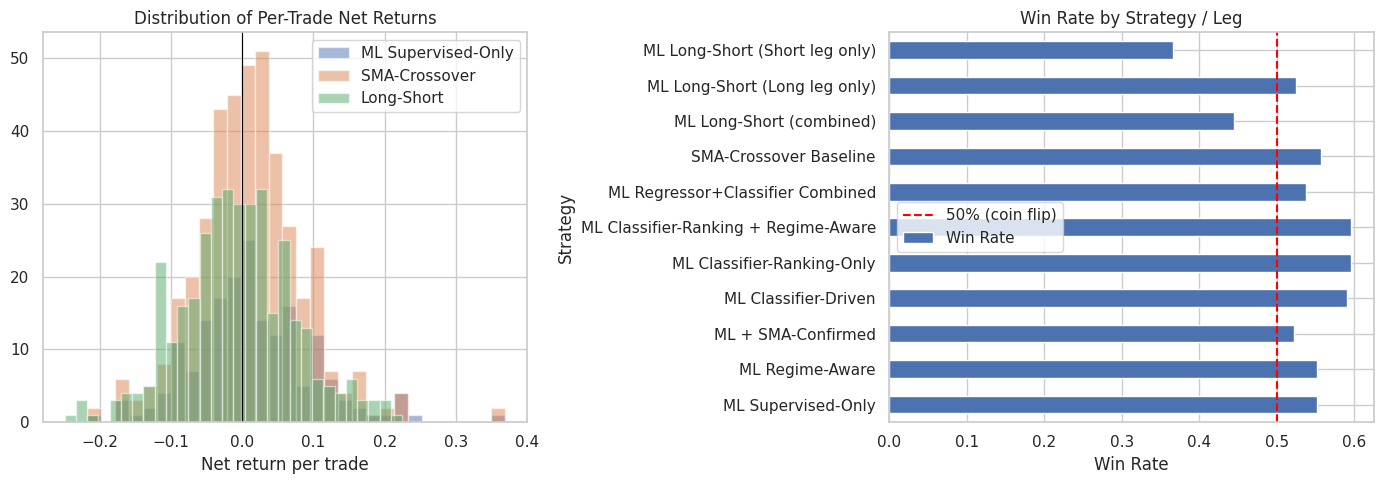

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, log, color in [("ML Supervised-Only", trade_log_supervised, "#4C72B0"),
                           ("SMA-Crossover", trade_log_sma, "#DD8452"),
                           ("Long-Short", trade_log_long_short, "#55A868")]:
    if len(log) > 0:
        axes[0].hist(log["net_return"], bins=30, alpha=0.5, label=label, color=color)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Distribution of Per-Trade Net Returns")
axes[0].set_xlabel("Net return per trade")
axes[0].legend()

trade_summary["Win Rate"].dropna().plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].axvline(0.5, color="red", linestyle="--", label="50% (coin flip)")
axes[1].set_title("Win Rate by Strategy / Leg")
axes[1].set_xlabel("Win Rate")
axes[1].legend()

plt.tight_layout()
plt.show()


### 13 £ Account Balance & Full Trade Ledger

Everything so far has been in percentage-return terms. This section makes it concrete: starting from an illustrative **£100,000**, exactly which stock was traded, when each position opened and closed, how many pounds were committed to it, and what it made or lost — plus a running account balance curve over the whole backtest, the same way a real brokerage statement would show it.

**Note on the £ allocation figure:** since the account compounds over time, "how many pounds go into a position" depends on the account's value at that point in the backtest, not a fixed starting amount every month. Each trade's `capital_allocated` uses the account balance as of the close of the trading day *before* that month's rebalance — a standard, slightly-simplified convention (it doesn't account for intra-day timing), stated here rather than left implicit.


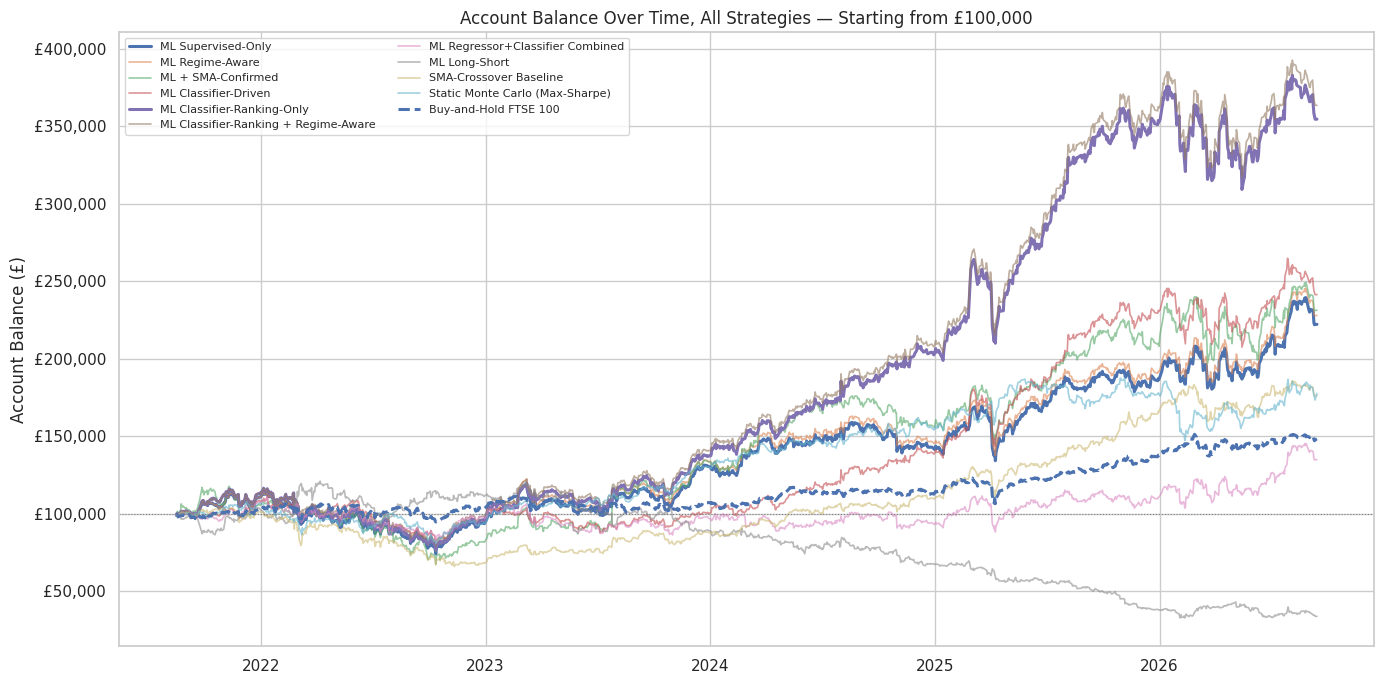

Starting balance: £100,000.00

  ML Classifier-Ranking + Regime-Aware   £363,356.02
  ML Classifier-Ranking-Only             £354,394.70
  ML Classifier-Driven                   £241,209.16
  ML + SMA-Confirmed                     £231,131.83
  ML Regime-Aware                        £227,761.62
  ML Supervised-Only                     £222,060.02
  Static Monte Carlo (Max-Sharpe)        £177,477.82
  SMA-Crossover Baseline                 £176,177.16
  Buy-and-Hold FTSE 100                  £148,192.88
  ML Regressor+Classifier Combined       £134,780.55
  ML Long-Short                          £33,718.05


In [ ]:
INITIAL_CAPITAL = 100_000.0

def compute_balance_curve(daily_returns: pd.Series, initial_capital: float = INITIAL_CAPITAL) -> pd.Series:
    """Convert a daily percentage-returns series into an actual currency balance curve."""
    return initial_capital * (1 + daily_returns).cumprod()


# Balance curves for EVERY strategy built in this notebook
all_strategy_returns = {
    "ML Supervised-Only": strategy_returns_supervised,
    "ML Regime-Aware": strategy_returns_regime_aware,
    "ML + SMA-Confirmed": strategy_returns_sma_confirmed,
    "ML Classifier-Driven": strategy_returns_classifier_driven,
    "ML Classifier-Ranking-Only": strategy_returns_classifier_ranking,
    "ML Classifier-Ranking + Regime-Aware": strategy_returns_classifier_ranking_regime,
    "ML Regressor+Classifier Combined": strategy_returns_combined,
    "ML Long-Short": strategy_returns_long_short,
    "SMA-Crossover Baseline": strategy_returns_sma,
    "Static Monte Carlo (Max-Sharpe)": static_max_sharpe_returns,
    "Buy-and-Hold FTSE 100": benchmark_bh_returns,
}
all_balance_curves = {name: compute_balance_curve(rets) for name, rets in all_strategy_returns.items()}

fig, ax = plt.subplots(figsize=(14, 7))
for name, curve in all_balance_curves.items():
    is_headline = name in ("ML Classifier-Ranking-Only", "ML Supervised-Only", "Buy-and-Hold FTSE 100")
    ax.plot(curve.index, curve.values, label=name,
            linewidth=2.2 if is_headline else 1.2,
            alpha=1.0 if is_headline else 0.6,
            linestyle="--" if name == "Buy-and-Hold FTSE 100" else "-")
ax.axhline(INITIAL_CAPITAL, color="grey", linewidth=0.8, linestyle=":")
ax.set_ylabel("Account Balance (£)")
ax.set_title(f"Account Balance Over Time, All Strategies — Starting from £{INITIAL_CAPITAL:,.0f}")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

print(f"Starting balance: £{INITIAL_CAPITAL:,.2f}\n")
final_balances = pd.Series({name: curve.iloc[-1] for name, curve in all_balance_curves.items()},
                            name="Final Balance (£)").sort_values(ascending=False)
for name, val in final_balances.items():
    print(f"  {name:<38s} £{val:,.2f}")


In [ ]:
def build_trade_ledger(signals: pd.DataFrame, prices: pd.DataFrame, returns: pd.DataFrame,
                        balance_curve: pd.Series, tx_cost: float = 0.001,
                        borrow_cost_annual: float = 0.0,
                        initial_capital: float = INITIAL_CAPITAL) -> pd.DataFrame:
    """
    Build a full currency-denominated trade ledger: one row per (ticker,
    holding period), showing exactly which stock was traded, the entry/exit
    dates, side (Long/Short), the weight assigned, how many pounds that
    weight represented at entry (using the actual compounded account
    balance as of the prior trading day -- see markdown note above), the
    trade\'s net return, and the resulting profit/loss in pounds.
    """
    if len(signals) == 0:
        return pd.DataFrame(columns=["entry_date", "exit_date", "ticker", "side", "weight",
                                      "capital_allocated", "net_return", "pnl_gbp", "balance_after"])

    rebalance_dates = signals.index.unique().sort_values()
    all_dates = returns.loc[returns.index >= rebalance_dates.min()].index

    ledger = []
    for i, reb_date in enumerate(rebalance_dates):
        period_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else all_dates.max()
        period_dates = all_dates[(all_dates >= reb_date) & (all_dates < period_end)]
        if len(period_dates) == 0:
            continue

        # Account balance as of the close of the prior trading day (pre-rebalance)
        prior_dates = balance_curve.index[balance_curve.index < reb_date]
        capital_at_entry = balance_curve.loc[prior_dates[-1]] if len(prior_dates) > 0 else initial_capital

        month_positions = signals.loc[[reb_date]].groupby("ticker")["weight"].sum()

        for ticker, weight in month_positions.items():
            if weight == 0 or ticker not in returns.columns:
                continue
            side = "Long" if weight > 0 else "Short"
            price_return = (1 + returns.loc[period_dates, ticker]).prod() - 1
            gross_return = price_return if side == "Long" else -price_return

            holding_days = len(period_dates)
            borrow_drag = (borrow_cost_annual / 252) * holding_days if side == "Short" else 0.0
            net_return = gross_return - tx_cost - borrow_drag

            capital_allocated = capital_at_entry * abs(weight)
            pnl_gbp = capital_allocated * net_return

            ledger.append({
                "entry_date": reb_date, "exit_date": period_dates.max(),
                "ticker": ticker, "side": side, "weight": weight,
                "capital_allocated": capital_allocated, "net_return": net_return,
                "pnl_gbp": pnl_gbp,
            })

    ledger_df = pd.DataFrame(ledger)
    # Running account balance AFTER each rebalance date\'s combined trades close
    if len(ledger_df) > 0:
        monthly_pnl = ledger_df.groupby("entry_date")["pnl_gbp"].sum()
        running_balance = initial_capital + monthly_pnl.cumsum()
        ledger_df["balance_after"] = ledger_df["entry_date"].map(running_balance)

    return ledger_df


trade_ledger_supervised = build_trade_ledger(monthly_signals, prices, returns,
                                              all_balance_curves["ML Supervised-Only"])

print(f"Full trade ledger: {len(trade_ledger_supervised)} individual positions")
trade_ledger_supervised.round(2)


Full trade ledger: 183 individual positions


,entry_date,exit_date,ticker,side,weight,capital_allocated,net_return,pnl_gbp,balance_after
0,2021-08-16,2021-08-31,RR.L,Long,0.32,31666.67,0.03,1016.48,100533.92
1,2021-08-16,2021-08-31,SMIN.L,Long,0.34,34166.67,-0.02,-707.52,100533.92
2,2021-08-16,2021-08-31,SN.L,Long,0.34,34166.67,0.01,224.96,100533.92
3,2021-09-01,2021-09-30,RR.L,Long,0.32,31850.87,0.22,6978.33,106113.16
4,2021-09-01,2021-09-30,SMIN.L,Long,0.34,34365.41,-0.00,-70.11,106113.16
...,...,...,...,...,...,...,...,...,...
178,2026-07-01,2026-07-31,SGE.L,Long,0.34,71427.94,0.19,13688.95,220399.35
179,2026-07-01,2026-07-31,SMIN.L,Long,0.34,71427.94,0.03,2216.50,220399.35
180,2026-08-03,2026-09-11,RR.L,Long,0.34,77271.99,-0.01,-769.26,215699.11
181,2026-08-03,2026-09-11,SGE.L,Long,0.34,77271.99,-0.02,-1284.15,215699.11


In [ ]:
# Export the full ledger to CSV for browsing outside the notebook (e.g. in Excel)
trade_ledger_supervised.to_csv("trade_ledger_ml_supervised.csv", index=False)
print("Saved: trade_ledger_ml_supervised.csv "
      "(in Colab, find this in the file browser on the left, or download it directly)")

# Optional, Colab only -- uncomment to trigger a direct browser download:
# from google.colab import files
# files.download("trade_ledger_ml_supervised.csv")


Saved: trade_ledger_ml_supervised.csv (in Colab, find this in the file browser on the left, or download it directly)


# 14 Master Consolidated Results Table

Everything from Sections 11.1-13 combined into a single reference table: portfolio-level risk/return metrics, trade-level statistics, and the actual £ account outcome, for every strategy built in this notebook.

Static Monte Carlo and Buy-and-Hold have no monthly rebalancing, so trade-level statistics (N Trades/Win Rate/Profit Factor) do not apply to them in the same sense and are shown as N/A rather than misleadingly computed as a single giant "trade".

> Add blockquote




In [ ]:
# Add both classifier-ranking variants into the main metrics comparison, so the
# master table below genuinely shows every strategy built in this notebook.
metrics_table.loc["ML Classifier-Ranking-Only"] = compute_backtest_metrics(strategy_returns_classifier_ranking)
metrics_table.loc["ML Classifier-Ranking + Regime-Aware"] = compute_backtest_metrics(strategy_returns_classifier_ranking_regime)


def apply_regime_scaling(signals: pd.DataFrame, regime_labels: pd.Series,
                          high_vol_scale: float = 0.5) -> pd.DataFrame:
    """Re-create the effective weights actually used by the regime-aware
    overlay inside backtest_strategy(), so a trade log can be built that
    matches what that strategy actually did."""
    scaled = signals.copy()
    scale_factors = [high_vol_scale if regime_labels.get(d, 2) == 0 else 1.0 for d in scaled.index]
    scaled["weight"] = scaled["weight"].values * np.array(scale_factors)
    return scaled


regime_aware_effective_signals = apply_regime_scaling(monthly_signals, regime_at_rebalance)
trade_log_regime_aware = build_trade_log(regime_aware_effective_signals, prices, returns, tx_cost=0.001)
trade_log_sma_confirmed = build_trade_log(sma_confirmed_signals, prices, returns, tx_cost=0.001)
trade_log_classifier_ranking = build_trade_log(classifier_ranking_signals, prices, returns, tx_cost=0.001)
trade_log_classifier_ranking_regime = build_trade_log(
    apply_regime_scaling(classifier_ranking_signals, regime_at_rebalance), prices, returns, tx_cost=0.001)

all_trade_summaries = {
    "ML Supervised-Only": summarise_trades(trade_log_supervised, "ML Supervised-Only"),
    "ML Regime-Aware": summarise_trades(trade_log_regime_aware, "ML Regime-Aware"),
    "ML + SMA-Confirmed": summarise_trades(trade_log_sma_confirmed, "ML + SMA-Confirmed"),
    "ML Classifier-Driven": summarise_trades(trade_log_classifier_driven, "ML Classifier-Driven"),
    "ML Classifier-Ranking-Only": summarise_trades(trade_log_classifier_ranking, "ML Classifier-Ranking-Only"),
    "ML Classifier-Ranking + Regime-Aware": summarise_trades(trade_log_classifier_ranking_regime, "ML Classifier-Ranking + Regime-Aware"),
    "ML Regressor+Classifier Combined": summarise_trades(trade_log_combined, "ML Regressor+Classifier Combined"),
    "ML Long-Short": summarise_trades(trade_log_long_short, "ML Long-Short"),
    "SMA-Crossover Baseline": summarise_trades(trade_log_sma, "SMA-Crossover Baseline"),
}

# Recompute balance curves including both newly-added classifier-ranking strategies
all_balance_curves["ML Classifier-Ranking-Only"] = compute_balance_curve(strategy_returns_classifier_ranking)
all_balance_curves["ML Classifier-Ranking + Regime-Aware"] = compute_balance_curve(strategy_returns_classifier_ranking_regime)
final_balance_all = pd.Series({name: curve.iloc[-1] for name, curve in all_balance_curves.items()},
                               name="Final Balance (£)")

# Explicit mapping: which underlying ML model actually drives each strategy's
# predictions. Added specifically so it is never necessary to reconstruct this
# from memory or from scattered code cells -- it is stated once, here, in the
# same table as every other result.
STRATEGY_MODEL_MAP = {
    "ML Supervised-Only": "XGBoost (regressor)",
    "ML Regime-Aware": "XGBoost (regressor)",
    "ML + SMA-Confirmed": "XGBoost (regressor) + SMA rule",
    "ML Classifier-Driven": best_tabular_clf_name,
    "ML Classifier-Ranking-Only": best_tabular_clf_name,
    "ML Classifier-Ranking + Regime-Aware": best_tabular_clf_name,
    "ML Regressor+Classifier Combined": f"XGBoost (regressor) + {best_tabular_clf_name}",
    "ML Long-Short": "XGBoost (regressor)",
    "SMA-Crossover Baseline": "None (non-ML technical rule)",
    "Static Monte Carlo (Max-Sharpe)": "None (classical optimisation, no ML)",
    "Buy-and-Hold FTSE 100": "None (passive benchmark)",
}

# Assemble the single master table
master_rows = []
for strategy in metrics_table.index:
    row = metrics_table.loc[strategy].to_dict()
    row["Model Used"] = STRATEGY_MODEL_MAP.get(strategy, "Unknown -- check STRATEGY_MODEL_MAP")
    row["Final Balance (£100k start)"] = final_balance_all.get(strategy, np.nan)
    if strategy in all_trade_summaries:
        ts = all_trade_summaries[strategy]
        row["N Trades"] = ts.get("N Trades", np.nan)
        win_rate_raw = ts.get("Win Rate")
        row["Win Rate"] = f"{win_rate_raw:.1%}" if win_rate_raw is not None else "N/A"
        row["Profit Factor"] = ts.get("Profit Factor", np.nan)
    else:
        row["N Trades"], row["Win Rate"], row["Profit Factor"] = "N/A", "N/A", "N/A"
    row["Strategy"] = strategy
    master_rows.append(row)

master_table = pd.DataFrame(master_rows).set_index("Strategy")
master_table = master_table.sort_values("Sharpe Ratio", ascending=False)

# Put Model Used right after the index for visibility, not buried at the end
cols = ["Model Used"] + [c for c in master_table.columns if c != "Model Used"]
master_table = master_table[cols]

pd.set_option("display.float_format", lambda x: f"{x:,.4f}" if isinstance(x, float) else str(x))
master_table


,Model Used,CAGR,Sharpe Ratio,Sortino Ratio,Max Drawdown,"VaR (95%, 1-day)",Final Value ($1 invested),Final Balance (£100k start),N Trades,Win Rate,Profit Factor
Strategy,,,,,,,,,,,
ML Classifier-Ranking + Regime-Aware,Random Forest (clf),0.2910,1.2491,1.7239,-0.3220,-0.0193,3.6336,"363,356.0203",183,59.6%,2.0006
ML Classifier-Ranking-Only,Random Forest (clf),0.2846,1.2055,1.6492,-0.3387,-0.0201,3.5439,"354,394.7011",183,59.6%,2.0006
ML Classifier-Driven,Random Forest (clf),0.1904,0.9241,1.2491,-0.2678,-0.0190,2.4121,"241,209.1558",149,59.1%,1.8802
ML Regime-Aware,XGBoost (regressor),0.1770,0.8587,1.1892,-0.3346,-0.0199,2.2776,"227,761.6152",183,55.2%,1.5805
ML Supervised-Only,XGBoost (regressor),0.1711,0.8222,1.1294,-0.3513,-0.0203,2.2206,"222,060.0222",183,55.2%,1.5805
Static Monte Carlo (Max-Sharpe),"None (classical optimisation, no ML)",0.1203,0.7600,1.0460,-0.2499,-0.0160,1.7748,"177,477.8187",N/A,N/A,N/A
ML + SMA-Confirmed,XGBoost (regressor) + SMA rule,0.1804,0.7363,1.0653,-0.4259,-0.0246,2.3113,"231,131.8281",113,52.2%,1.6612
SMA-Crossover Baseline,None (non-ML technical rule),0.1186,0.6908,0.8936,-0.3650,-0.0173,1.7618,"176,177.1562",409,55.7%,1.4344
Buy-and-Hold FTSE 100,None (passive benchmark),0.0810,0.6843,0.8653,-0.1343,-0.0123,1.4819,"148,192.8785",N/A,N/A,N/A


# 15 Diagnostic: Ranking-Only vs. Threshold-Gated vs. Regime-Aware Classifier Strategy

This section brings together every angle tested on the classifier-ranking approach, in one place, with the full metric set (not just CAGR/Sharpe/Max Drawdown): the original threshold-gated version, the ranking-only version (no confidence threshold), and a new third variant that adds the same HMM regime exposure overlay used by ML Regime-Aware on top of the ranking-only signal. This directly tests whether the two best ideas in this project -- ranking over calibration, and regime-based risk scaling -- combine additively, or whether one supersedes the other.


In [ ]:
# Trade-level logs for all three classifier variants (build_trade_log is
# available by this point in the notebook, unlike at the original position
# of this diagnostic -- moved here specifically so every tool it needs
# already exists, rather than duplicating logic earlier).
trade_log_classifier_ranking_regime = build_trade_log(
    apply_regime_scaling(classifier_ranking_signals, regime_at_rebalance),
    prices, returns, tx_cost=0.001)

classifier_variants = {
    "ML Classifier-Driven (threshold > 0.5)": (strategy_returns_classifier_driven, trade_log_classifier_driven),
    "ML Classifier-Ranking-Only (no threshold)": (strategy_returns_classifier_ranking, trade_log_classifier_ranking),
    "ML Classifier-Ranking + Regime-Aware": (strategy_returns_classifier_ranking_regime, trade_log_classifier_ranking_regime),
}

rows = []
for name, (rets, tlog) in classifier_variants.items():
    metrics = compute_backtest_metrics(rets)
    trades = summarise_trades(tlog, name)
    win_rate_val = trades.get("Win Rate")
    win_rate_str = f"{win_rate_val:.1%}" if win_rate_val is not None else "N/A"
    rows.append({
        "Strategy": name,
        "CAGR": metrics["CAGR"], "Sharpe Ratio": metrics["Sharpe Ratio"],
        "Sortino Ratio": metrics["Sortino Ratio"], "Max Drawdown": metrics["Max Drawdown"],
        "VaR (95%, 1-day)": metrics["VaR (95%, 1-day)"],
        "Final Value ($1 invested)": metrics["Final Value ($1 invested)"],
        "N Trades": trades.get("N Trades", "N/A"),
        "Win Rate": win_rate_str,
        "Profit Factor": trades.get("Profit Factor", "N/A"),
    })

classifier_comparison_full = pd.DataFrame(rows).set_index("Strategy")
print("Full comparison -- does removing the confidence threshold help, and does adding")
print("the regime overlay help further on top of that?")
classifier_comparison_full.round(4)


Full comparison -- does removing the confidence threshold help, and does adding
the regime overlay help further on top of that?


,CAGR,Sharpe Ratio,Sortino Ratio,Max Drawdown,"VaR (95%, 1-day)",Final Value ($1 invested),N Trades,Win Rate,Profit Factor
Strategy,,,,,,,,,
ML Classifier-Driven (threshold > 0.5),0.1904,0.9241,1.2491,-0.2678,-0.0190,2.4121,149,59.1%,1.8802
ML Classifier-Ranking-Only (no threshold),0.2846,1.2055,1.6492,-0.3387,-0.0201,3.5439,183,59.6%,2.0006
ML Classifier-Ranking + Regime-Aware,0.2910,1.2491,1.7239,-0.3220,-0.0193,3.6336,183,59.6%,2.0006


In [ ]:
# Export the master table for pasting directly into a report
master_table.to_csv("master_consolidated_results.csv")
print("Saved: master_consolidated_results.csv")
print()

top_row = master_table.iloc[0]
top_strategy = master_table.index[0]
print(f"Best strategy by Sharpe Ratio: {top_strategy}")
print(f"  Sharpe: {top_row['Sharpe Ratio']:.4f}, "
      f"CAGR: {top_row['CAGR']:.4f}, "
      f"Final Balance: £{top_row['Final Balance (£100k start)']:,.2f}")


Saved: master_consolidated_results.csv

Best strategy by Sharpe Ratio: ML Classifier-Ranking + Regime-Aware
  Sharpe: 1.2491, CAGR: 0.2910, Final Balance: £363,356.02


# 16. Walk-Forward Robustness Check

The single train/validation/test split used throughout this notebook answers "how did the strategy do over one specific test period?" — but says nothing about whether that result is a stable pattern or an artefact of which period happened to be held out. Walk-forward validation addresses this directly: the model is refit on an **expanding window** and evaluated on each of several *sequential, non-overlapping* blocks, so the same comparison (ML vs. SMA vs. Buy-and-Hold) can be checked for consistency across different sub-periods rather than trusting a single split.

**Scope, stated explicitly:** to keep this tractable within the project's time budget, walk-forward is applied to **XGBoost only** (the model driving the trading strategy) rather than all four models, and clustering/universe selection is **not** re-run per fold (the same final universe and cluster assignments from Section 5 are reused throughout) — only the supervised model is refit per fold. This is a deliberate simplification, not an oversight; a fully rigorous version would also re-run universe selection per fold, at proportionally higher computational cost.


In [ ]:
N_FOLDS = 3

all_dates = model_df.index.unique().sort_values()
n_blocks = N_FOLDS + 1  # first block is train-only, never evaluated
block_edges = [all_dates[min(int(len(all_dates) * i / n_blocks), len(all_dates) - 1)]
               for i in range(n_blocks + 1)]
block_edges[-1] = all_dates[-1]

wf_model_results = {}
wf_strategy_results = {}

xgb_params = tuned_models["XGBoost"].named_steps["model"].get_params()

for fold in range(1, n_blocks):
    train_cutoff = block_edges[fold]
    test_start = train_cutoff
    test_end = block_edges[fold + 1]

    fold_train = model_df[model_df.index <= train_cutoff]
    fold_test = model_df[(model_df.index > test_start) & (model_df.index <= test_end)]

    if len(fold_test) == 0 or len(fold_train) == 0:
        continue

    fold_pipe = build_pipeline(XGBRegressor(**xgb_params))
    fold_pipe.fit(fold_train[FEATURE_COLS], fold_train[TARGET_COL])

    fold_pred = fold_pipe.predict(fold_test[FEATURE_COLS])
    wf_model_results[f"Fold {fold}"] = {
        "test_start": test_start.date(), "test_end": test_end.date(),
        **evaluate_predictions(fold_test[TARGET_COL], fold_pred),
    }

    # Re-run the cluster+optimizer strategy and SMA baseline on this fold's block only
    fold_signals = generate_cluster_optimizer_signals(
        fold_test, fold_pipe, FEATURE_COLS, final_universe_clusters, returns, cov_window=60)
    fold_ml_returns = backtest_strategy(fold_signals, prices, returns, tx_cost=0.001) \
        if len(fold_signals) > 0 else pd.Series(dtype="float64")

    fold_rebalance_dates = fold_signals.index.unique().sort_values() if len(fold_signals) > 0 else pd.DatetimeIndex([])
    fold_sma_signals = generate_sma_signals(full_feature_df, FINAL_UNIVERSE, fold_rebalance_dates)
    fold_sma_returns = backtest_strategy(fold_sma_signals, prices, returns, tx_cost=0.001) \
        if len(fold_sma_signals) > 0 else pd.Series(dtype="float64")

    fold_bh_returns = benchmark_returns.reindex(fold_ml_returns.index) if len(fold_ml_returns) > 0 else pd.Series(dtype="float64")

    # Also refit the actual BEST-PERFORMING strategy's model (the classifier
    # driving Classifier-Ranking-Only) per fold, using sklearn.base.clone to
    # get a fresh, unfitted copy of whichever classifier type was selected
    # (Logistic Regression / Random Forest / XGBoost), regardless of which
    # one it turned out to be -- this closes the gap where walk-forward
    # previously only ever validated the XGBoost-driven strategies, not the
    # actual top performer.
    from sklearn.base import clone
    fold_clf_estimator = clone(best_tabular_clf_pipe.named_steps["model"])
    fold_clf_pipe = build_classification_pipeline(
        fold_clf_estimator, add_polynomial=(best_tabular_clf_name == "Logistic Regression"))
    fold_train_clf_target = (fold_train[TARGET_COL] > 0).astype(int)
    fold_clf_pipe.fit(fold_train[FEATURE_COLS], fold_train_clf_target)

    fold_clf_signals = generate_classifier_ranking_signals(
        fold_test, fold_clf_pipe, FEATURE_COLS, final_universe_clusters)
    fold_clf_returns = backtest_strategy(fold_clf_signals, prices, returns, tx_cost=0.001) \
        if len(fold_clf_signals) > 0 else pd.Series(dtype="float64")

    wf_strategy_results[f"Fold {fold}"] = {
        "ML (XGBoost) Sharpe": compute_backtest_metrics(fold_ml_returns)["Sharpe Ratio"] if len(fold_ml_returns) > 0 else np.nan,
        "ML (Classifier-Ranking) Sharpe": compute_backtest_metrics(fold_clf_returns)["Sharpe Ratio"] if len(fold_clf_returns) > 0 else np.nan,
        "SMA Sharpe": compute_backtest_metrics(fold_sma_returns)["Sharpe Ratio"] if len(fold_sma_returns) > 0 else np.nan,
        "Buy-Hold Sharpe": compute_backtest_metrics(fold_bh_returns)["Sharpe Ratio"] if len(fold_bh_returns) > 0 else np.nan,
        "ML (XGBoost) CAGR": compute_backtest_metrics(fold_ml_returns)["CAGR"] if len(fold_ml_returns) > 0 else np.nan,
        "ML (Classifier-Ranking) CAGR": compute_backtest_metrics(fold_clf_returns)["CAGR"] if len(fold_clf_returns) > 0 else np.nan,
        "SMA CAGR": compute_backtest_metrics(fold_sma_returns)["CAGR"] if len(fold_sma_returns) > 0 else np.nan,
        "Buy-Hold CAGR": compute_backtest_metrics(fold_bh_returns)["CAGR"] if len(fold_bh_returns) > 0 else np.nan,
    }

wf_model_table = pd.DataFrame(wf_model_results).T
wf_strategy_table = pd.DataFrame(wf_strategy_results).T

print("Model performance per walk-forward fold:")
print(wf_model_table)
print()
print("Strategy Sharpe/CAGR per walk-forward fold:")
print(wf_strategy_table.round(4))


Model performance per walk-forward fold:
        test_start    test_end    MAE   RMSE      R2 Directional Accuracy
Fold 1  2019-12-06  2022-02-23 0.0775 0.1149 -0.0162               0.4937
Fold 2  2022-02-23  2024-05-16 0.0608 0.0816 -0.0630               0.4824
Fold 3  2024-05-16  2026-08-13 0.0594 0.0786 -0.0329               0.5591

Strategy Sharpe/CAGR per walk-forward fold:
        ML (XGBoost) Sharpe  ML (Classifier-Ranking) Sharpe  SMA Sharpe  \
Fold 1               0.6726                          0.7722      0.6100   
Fold 2               1.2174                          1.2590      0.9823   
Fold 3               1.3663                          1.2697      1.5511   

        Buy-Hold Sharpe  ML (XGBoost) CAGR  ML (Classifier-Ranking) CAGR  \
Fold 1           0.4390             0.1691                        0.2023   
Fold 2           0.6901             0.2822                        0.2885   
Fold 3           0.9522             0.2960                        0.2729   

        SMA 

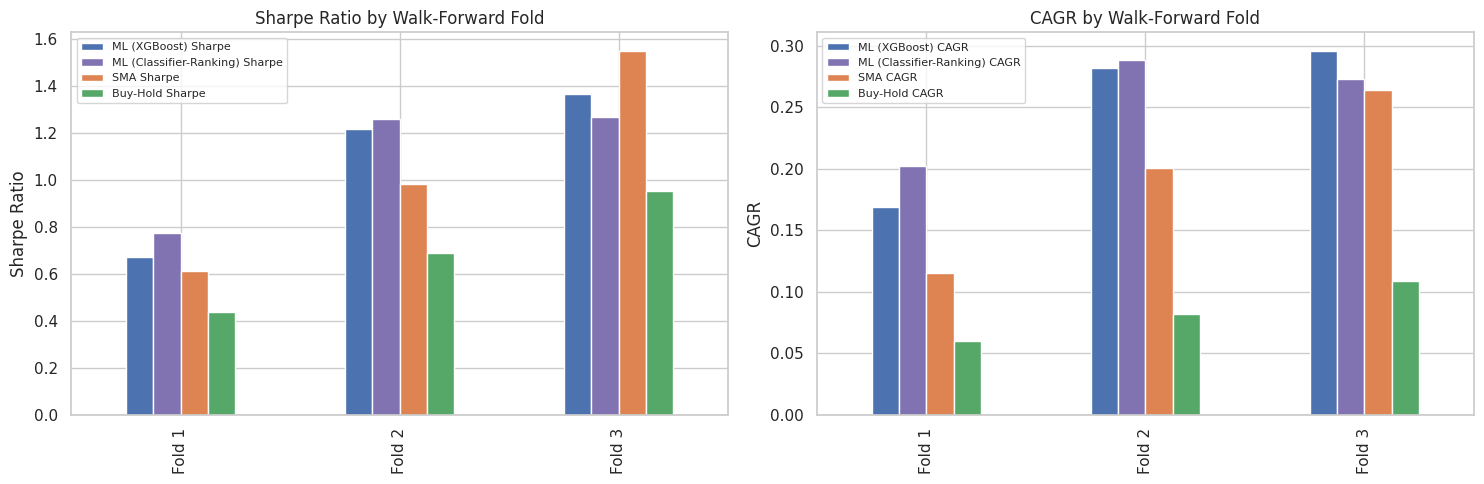

Interpretation guide: both ML variants (XGBoost-driven and Classifier-Ranking-driven) are now walk-forward tested, not just the XGBoost one -- if the Classifier-Ranking strategy consistently beats both the SMA baseline and Buy-and-Hold across ALL folds, that is strong evidence its earlier single-split result (Section 13.6) reflects a genuine, period-independent pattern rather than one favourable test window.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sharpe_cols = ["ML (XGBoost) Sharpe", "ML (Classifier-Ranking) Sharpe", "SMA Sharpe", "Buy-Hold Sharpe"]
cagr_cols = ["ML (XGBoost) CAGR", "ML (Classifier-Ranking) CAGR", "SMA CAGR", "Buy-Hold CAGR"]
plot_colors = ["#4C72B0", "#8172B2", "#DD8452", "#55A868"]

wf_strategy_table[sharpe_cols].plot(kind="bar", ax=axes[0], color=plot_colors)
axes[0].set_title("Sharpe Ratio by Walk-Forward Fold")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Sharpe Ratio")
axes[0].legend(fontsize=8)

wf_strategy_table[cagr_cols].plot(kind="bar", ax=axes[1], color=plot_colors)
axes[1].set_title("CAGR by Walk-Forward Fold")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("CAGR")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Interpretation guide: both ML variants (XGBoost-driven and Classifier-Ranking-driven) are "
      "now walk-forward tested, not just the XGBoost one -- if the Classifier-Ranking strategy "
      "consistently beats both the SMA baseline and Buy-and-Hold across ALL folds, that is strong "
      "evidence its earlier single-split result (Section 13.6) reflects a genuine, period-independent "
      "pattern rather than one favourable test window.")
